# Lab01 - sprint 1

Исследуем quality, alcohol и volatile_acidity в UCI Wine Quality.
Исходные разделы участников собраны ниже с едиными путями к данным и исправлениями расчётов.
Код длинных ячеек свёрнут в JupyterLab; его можно раскрыть.

1. [Quality](#rv01)
2. [Alcohol](#rv02)
3. [Volatile acidity](#rv03)
4. [Итоги первого спринта](#resume1)
5. [Второй спринт: данные и модели](#sprint2)
6. [Генератор](#generator)
7. [Проверка на реальных данных](#comparison)
8. [Сходимость](#convergence)
9. [Отбор с отклонением](#rejection)
10. [Итоги второго спринта](#resume2)

Для запуска: `python scripts/download_data.py`, затем Restart Kernel and Run All Cells.
Все строки сохраняем, включая совпадающие. Датасет считаем конечной генеральной совокупностью
только для учебных опытов с выборками. Выводы не распространяются автоматически на все вина.
Тесты предполагают независимые наблюдения; неизвестные партии могут нарушать это допущение.
Анализ первого спринта использует полный набор. Test второго спринта отложен от обучения,
но не является новыми, ранее не просмотренными данными для всего исследования.

In [1]:
from pathlib import Path
import sys, platform, importlib.metadata
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
for folder in ['reports/tables', 'reports/figures', 'data/processed']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version())
print({name: importlib.metadata.version(name) for name in
       ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn']})

Python: 3.12.14
{'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}


<a id="rv01"></a>

## Random Variable 01 (quality)

Источник раздела: [01_quality.ipynb](sprint1/01_quality.ipynb).

**Роль:** Инфохимик года № 1 - статистик-эмпирик  
**Датасет:** Wine Quality (Vinho Verde, Portugal), Cortez et al. (2009)  
**Целевая переменная:** quality - сенсорная оценка качества вина

### Description (природа события)

`quality` - порядковая оценка качества. Для случайно выбранной строки обозначим её через $Q$.
Случайность относится к выбору пробы: у уже записанной строки оценка фиксирована.
По одному содержанию спирта оценку точно не восстановить: при одинаковой крепости встречаются разные баллы.
Это не доказательство невозможности любой детерминированной модели.

Среднее и дисперсию используем с допущением о сопоставимых расстояниях между соседними баллами.
Частоты и медиана сохраняют смысл без этого допущения.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.plotting import use_style
use_style()
df = load_wines(ROOT / 'data/raw').rename(columns=lambda c: c.replace('_', ' ')).rename(columns={'wine type': 'color'})
red = df.loc[df.color.eq('red')].copy()
white = df.loc[df.color.eq('white')].copy()
print({'rows': len(df), 'missing': int(df.isna().sum().sum()), 'duplicates': int(df.duplicated().sum())})
display(df.head())

{'rows': 6497, 'missing': 0, 'duplicates': 1177}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [3]:
df.info() #проверка даннх на вменяемость

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


In [4]:
print("Пропуски всего:", df.isna().sum().sum())

print("Дубликаты:     ", df.duplicated().sum())
print("Размер:        ", df.shape)

Пропуски всего: 0
Дубликаты:      1177
Размер:         (6497, 13)


### EDA & Distribution

Основные статистики, форма распределения, ECDF.

In [5]:
q = df["quality"]

print("Тип данных:      ", q.dtype)
print("Наблюдений:      ", q.count())
print("Пропусков:       ", q.isna().sum())
print("Уникальные оценки:", sorted(q.unique()))

q.describe()

Тип данных:       int64
Наблюдений:       6497
Пропусков:        0
Уникальные оценки: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


count    6497.000000
mean        5.818378
std         0.873255
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         9.000000
Name: quality, dtype: float64

In [6]:
# Получаем оценки качества без пропусков
q = df["quality"].dropna()

# Ключевые описательные статистики quality
print(f"Среднее:          {q.mean():.4f}")
print(f"Медиана:          {q.median():.4f}")
print(f"Мода:             {q.mode().tolist()}")
print(f"Дисперсия:        {q.var():.4f}")
print(f"Стд. отклонение:  {q.std():.4f}")
print(f"Асимметрия:       {stats.skew(q):.4f}")
print(f"Эксцесс:          {stats.kurtosis(q):.4f}")

# Количество наблюдений и доля каждого значения quality
quality_counts = q.value_counts().sort_index()
quality_shares = q.value_counts(normalize=True).sort_index() * 100

quality_table = pd.DataFrame({
    "Количество": quality_counts,
    "Доля, %": quality_shares
})

print(f"\nОбщее количество наблюдений: {q.count()}")
display(quality_table.round(2))

Среднее:          5.8184
Медиана:          6.0000
Мода:             [6]
Дисперсия:        0.7626
Стд. отклонение:  0.8733
Асимметрия:       0.1896
Эксцесс:          0.2312

Общее количество наблюдений: 6497


,Количество,"Доля, %"
quality,,
3,30,0.46
4,216,3.32
5,2138,32.91
6,2836,43.65
7,1079,16.61
8,193,2.97
9,5,0.08


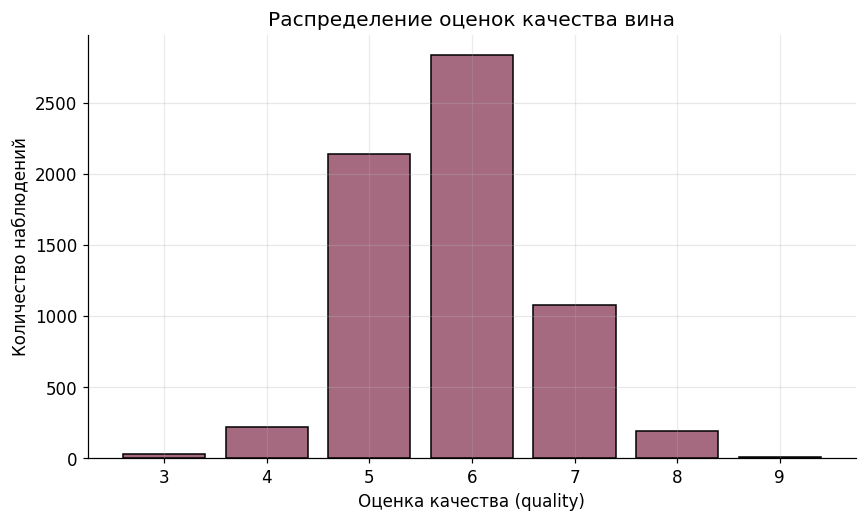

In [7]:
# гистограмма и в ней мы считаем, сколько раз встречается каждая оценка, и сортируем по возрастанию
quality_counts = q.value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    quality_counts.index,
    quality_counts.values,
    edgecolor="black"
)

plt.title("Распределение оценок качества вина")
plt.xlabel("Оценка качества (quality)")
plt.ylabel("Количество наблюдений")
plt.xticks(quality_counts.index)
plt.grid(axis="y", alpha=0.3)
plt.show()

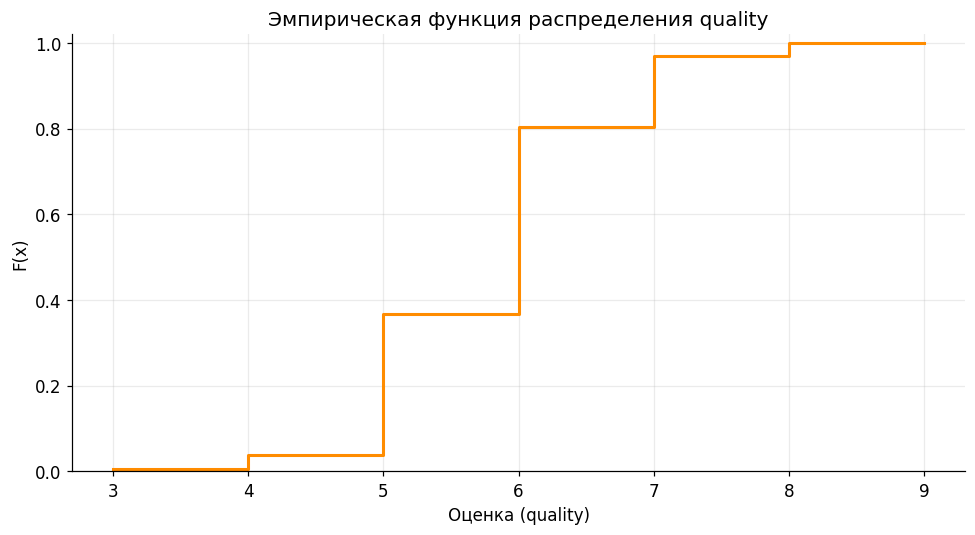

In [8]:
# Сортируем здесь всеее значения quality по возрастанию
x, counts = np.unique(q.to_numpy(), return_counts=True)
# Для каждой точки считаем долю наблюдений, не превышающих её
# (i / N - это и есть эмпирическая функция распределения)
y = np.cumsum(counts) / counts.sum()

# Ну тут строился ступенчатый график: where="post" - это знач ступенька идёт вправо
fig, ax = plt.subplots()
ax.step(x, y, where="post", color="darkorange", linewidth=2)
ax.set_title("Эмпирическая функция распределения quality")
ax.set_xlabel("Оценка (quality)")
ax.set_ylabel("F(x)")
ax.set_xticks(sorted(q.unique()))
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

### Вывод по исследовательскому анализу данных (EDA)

Переменная `quality` принимает целочисленные значения от 3 до 9 в рассматриваемом датасете. Это дискретная порядковая шкала: оценки упорядочены, но равные расстояния между баллами не обязательно соответствуют равным различиям в восприятии качества.

Основные описательные статистики и доли отдельных оценок приведены в таблицах выше. Гистограмма и эмпирическая функция распределения показывают, какие оценки встречаются чаще и как накапливается доля наблюдений.

Результат теста Д’Агостино-Пирсона приведён в следующей ячейке. Статистическое отклонение от нормального распределения не означает, что данные непригодны для анализа: необходимо учитывать дискретность шкалы, большой объём выборки и предположения конкретных статистических методов.

In [9]:
# Проверка нормальности распределения quality
# Тест Д'Агостино-Пирсона проверяет нулевую гипотезу о нормальности.

q = df["quality"].dropna()
alpha = 0.05

normality_result = stats.normaltest(q)

print(f"Количество наблюдений: {len(q)}")
print(f"Статистика теста: {normality_result.statistic:.4f}")
print(f"p-value: {normality_result.pvalue:.6g}")
print(f"Уровень значимости alpha: {alpha}")

if normality_result.pvalue < alpha:
    print(
        "Решение: отвергаем гипотезу о нормальности "
        "на уровне значимости 0.05."
    )
else:
    print(
        "Решение: нет достаточных оснований отвергнуть "
        "гипотезу о нормальности на уровне значимости 0.05."
    )

print(
    "Примечание: quality - дискретная порядковая переменная. "
    "Результат теста следует интерпретировать с учётом этого свойства."
)

Количество наблюдений: 6497
Статистика теста: 50.3590
p-value: 1.16061e-11
Уровень значимости alpha: 0.05
Решение: отвергаем гипотезу о нормальности на уровне значимости 0.05.
Примечание: quality - дискретная порядковая переменная. Результат теста следует интерпретировать с учётом этого свойства.


### Independence & Estimations

При отборе с возвращением $\operatorname{Var}(\bar Q_n)=\sigma^2/n$.
Без возвращения она равна $\sigma^2(N-n)/(n(N-1))$, где $\sigma^2$ рассчитана с делителем $N$.
Повторный эксперимент иллюстрирует состоятельность среднего, но не заменяет доказательство предела.

In [10]:
# Моделирование выборок с возвращением и без возвращения

SEED = 42
N_REPEATS = 1000
SAMPLE_SIZES = [10, 30, 50, 100, 300, 500, 1000, 6497]

population = df["quality"].dropna().to_numpy(dtype=float)
N = len(population)
mu = population.mean()
sigma2 = population.var(ddof=0)

rng = np.random.default_rng(SEED)
results = []

for n in SAMPLE_SIZES:
    if n > N:
        continue

    means_wr = np.empty(N_REPEATS)
    means_wor = np.empty(N_REPEATS)

    for i in range(N_REPEATS):
        means_wr[i] = rng.choice(
            population, size=n, replace=True
        ).mean()

        means_wor[i] = rng.choice(
            population, size=n, replace=False
        ).mean()

    # Теоретическая SE среднего
    se_wr = np.sqrt(sigma2 / n)
    se_wor = np.sqrt(
        sigma2 / n * (N - n) / (N - 1)
    )

    # RMSE отдельной оценки среднего относительно mu
    rmse_wr = np.sqrt(np.mean((means_wr - mu) ** 2))
    rmse_wor = np.sqrt(np.mean((means_wor - mu) ** 2))

    results.append({
        "n": n,
        "Среднее WR": means_wr.mean(),
        "Среднее WOR": means_wor.mean(),
        "Смещение WR": means_wr.mean() - mu,
        "Смещение WOR": means_wor.mean() - mu,
        "SD средних WR": means_wr.std(ddof=1),
        "SD средних WOR": means_wor.std(ddof=1),
        "RMSE WR": rmse_wr,
        "RMSE WOR": rmse_wor,
        "Теоретическая SE WR": se_wr,
        "Теоретическая SE WOR": se_wor
    })

sampling_results = pd.DataFrame(results)

print(f"Размер полной совокупности: {N}")
print(f"Среднее полной совокупности: {mu:.6f}")
print(f"Число повторений для каждого n: {N_REPEATS}")

display(sampling_results.round(5))

Размер полной совокупности: 6497
Среднее полной совокупности: 5.818378
Число повторений для каждого n: 1000


,n,Среднее WR,Среднее WOR,Смещение WR,Смещение WOR,SD средних WR,SD средних WOR,RMSE WR,RMSE WOR,Теоретическая SE WR,Теоретическая SE WOR
0,10,5.82320,5.80870,0.00482,-0.00968,0.27235,0.28996,0.27226,0.28998,0.27613,0.27593
1,30,5.83157,5.80930,0.01319,-0.00908,0.16180,0.15578,0.16226,0.15597,0.15942,0.15907
2,50,5.81244,5.81092,-0.00594,-0.00746,0.12424,0.12299,0.12432,0.12315,0.12349,0.12302
3,100,5.82137,5.81947,0.00299,0.00109,0.08866,0.08528,0.08866,0.08524,0.08732,0.08665
4,300,5.82009,5.81737,0.00171,-0.00101,0.04953,0.05115,0.04953,0.05113,0.05041,0.04924
5,500,5.81700,5.81855,-0.00138,0.00017,0.03823,0.03778,0.03824,0.03776,0.03905,0.03752
6,1000,5.81940,5.81919,0.00103,0.00081,0.02756,0.02553,0.02756,0.02553,0.02761,0.02540
7,6497,5.81823,5.81838,-0.00014,0.00000,0.01087,0.00000,0.01086,0.00000,0.01083,0.00000


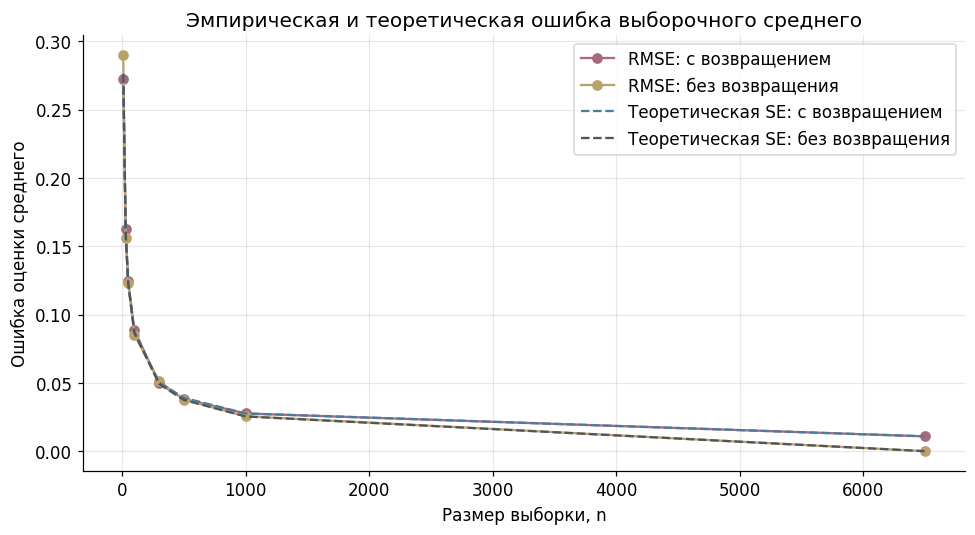

In [11]:
# Сравнение эмпирической RMSE с теоретической стандартной ошибкой

plt.figure(figsize=(9, 5))

plt.plot(
    sampling_results["n"],
    sampling_results["RMSE WR"],
    "o-",
    label="RMSE: с возвращением"
)

plt.plot(
    sampling_results["n"],
    sampling_results["RMSE WOR"],
    "o-",
    label="RMSE: без возвращения"
)

plt.plot(
    sampling_results["n"],
    sampling_results["Теоретическая SE WR"],
    "--",
    label="Теоретическая SE: с возвращением"
)

plt.plot(
    sampling_results["n"],
    sampling_results["Теоретическая SE WOR"],
    "--",
    label="Теоретическая SE: без возвращения"
)

plt.xlabel("Размер выборки, n")
plt.ylabel("Ошибка оценки среднего")
plt.title("Эмпирическая и теоретическая ошибка выборочного среднего")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Sampling

Полный датасет считаем конечной генеральной совокупностью для учебного отбора.

In [12]:
# Сравнение полной совокупности и двух случайных выборок

comparison_rng = np.random.default_rng(2026)

population = df["quality"].dropna().to_numpy(dtype=float)
n = 500

sample_wr = comparison_rng.choice(
    population, size=n, replace=True
)
sample_wor = comparison_rng.choice(
    population, size=n, replace=False
)

quality_values = sorted(np.unique(population))

def calculate_metrics(data, name, is_population=False):
    data = np.asarray(data, dtype=float)

    result = {
        "Данные": name,
        "Объём": len(data),
        "Среднее": np.mean(data),
        "Медиана": np.median(data),
        "Дисперсия": np.var(
            data, ddof=0 if is_population else 1
        )
    }

    for value in quality_values:
        result[f"Доля оценки {int(value)}, %"] = (
            np.mean(data == value) * 100
        )

    return result

comparison_table = pd.DataFrame([
    calculate_metrics(
        population, "Полный датасет", is_population=True
    ),
    calculate_metrics(
        sample_wr, "Выборка с возвращением"
    ),
    calculate_metrics(
        sample_wor, "Выборка без возвращения"
    )
])

display(comparison_table.round(3))

,Данные,Объём,Среднее,Медиана,Дисперсия,"Доля оценки 3, %","Доля оценки 4, %","Доля оценки 5, %","Доля оценки 6, %","Доля оценки 7, %","Доля оценки 8, %","Доля оценки 9, %"
0,Полный датасет,6497,5.818,6.0,0.762,0.462,3.325,32.907,43.651,16.608,2.971,0.077
1,Выборка с возвращением,500,5.816,6.0,0.840,1.000,3.400,32.000,44.600,14.800,4.000,0.200
2,Выборка без возвращения,500,5.916,6.0,0.766,0.400,2.200,30.200,43.400,20.200,3.600,0.000


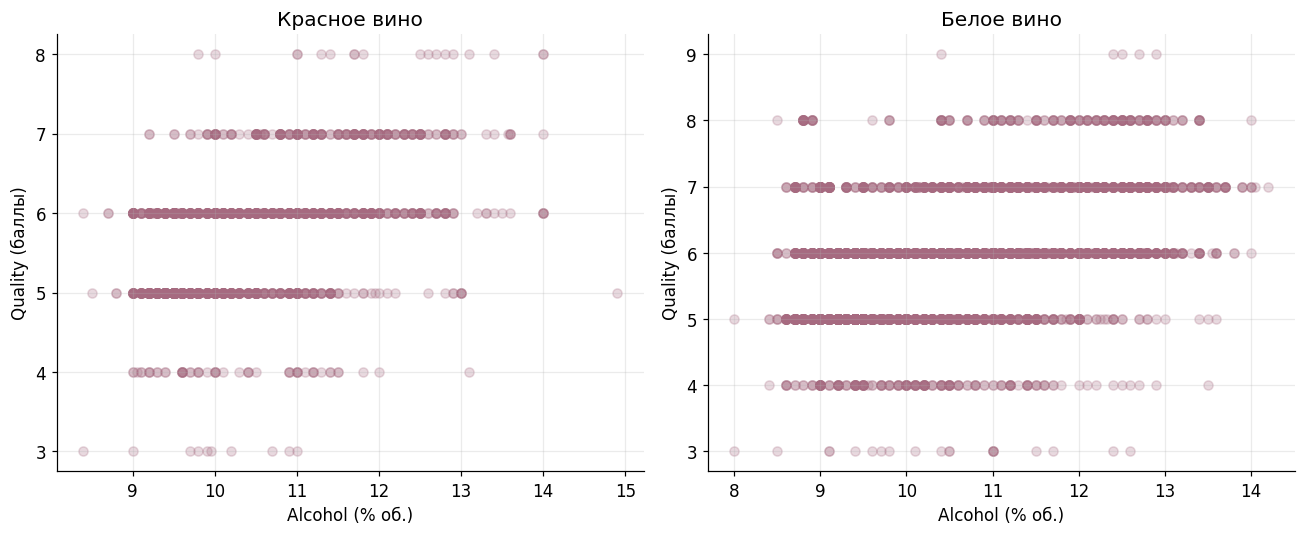

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, color in zip(axes, ["red", "white"]):
    subset = df.loc[df["color"] == color]

    ax.scatter(
        subset["alcohol"],
        subset["quality"],
        alpha=0.25
    )

    ax.set_title(
        "Красное вино" if color == "red"
        else "Белое вино"
    )
    ax.set_xlabel("Alcohol (% об.)")
    ax.set_ylabel("Quality (баллы)")

plt.tight_layout()
plt.show()

In [14]:
from scipy import stats
import pandas as pd

correlation_results = []

for color in ["red", "white"]:
    subset = df.loc[
        df["color"] == color,
        ["alcohol", "quality"]
    ].dropna()

    # Корреляция Пирсона: линейная связь числовых переменных
    pearson_r, pearson_p = stats.pearsonr(
        subset["alcohol"],
        subset["quality"]
    )

    # Корреляция Спирмена: связь между рангами
    spearman_r, spearman_p = stats.spearmanr(
        subset["alcohol"],
        subset["quality"]
    )

    correlation_results.append({
        "Тип вина": color,
        "Объём": len(subset),
        "Пирсон r": pearson_r,
        "p-value Пирсона": pearson_p,
        "Спирмен ρ": spearman_r,
        "p-value Спирмена": spearman_p
    })

correlation_table = pd.DataFrame(correlation_results)

display(correlation_table.round(5))

,Тип вина,Объём,Пирсон r,p-value Пирсона,Спирмен ρ,p-value Спирмена
0,red,1599,0.47617,0.0,0.47853,0.0
1,white,4898,0.43557,0.0,0.44037,0.0


### Интерпретация переменной quality

Переменная `quality` представляет собой оценку качества вина по шкале от 0 до 10. В исследуемом датасете наблюдаемые значения находятся в диапазоне от 3 до 9. Эта переменная имеет порядковый характер: значения отражают порядок оценок, но расстояния между соседними оценками не обязательно являются одинаковыми с точки зрения восприятия качества.

В дальнейшем среднее и дисперсия используются как описательные характеристики при условном допущении, что числовые различия между соседними оценками можно приближённо трактовать как сопоставимые. Это допущение упрощает статистическое сравнение, но не превращает порядковую шкалу в интервальную и должно учитываться при интерпретации результатов.

Стандартизация переменной, например с помощью z-преобразования, меняет её масштаб, но не устраняет дискретность и не делает распределение нормальным. Поэтому нормальность следует проверять отдельно, а результаты статистических тестов интерпретировать с учётом свойств данных.

In [15]:
# Разделение наблюдений по цвету вина

kr = df.loc[df["color"] == "red", "quality"].dropna()
bl = df.loc[df["color"] == "white", "quality"].dropna()

print("Красное вино:")
print(kr.describe().round(3))

print("\nБелое вино:")
print(bl.describe().round(3))

print(f"\nОбъём красного вина: {len(kr)}")
print(f"Объём белого вина: {len(bl)}")

Красное вино:
count    1599.000
mean        5.636
std         0.808
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         8.000
Name: quality, dtype: float64

Белое вино:
count    4898.000
mean        5.878
std         0.886
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000
Name: quality, dtype: float64

Объём красного вина: 1599
Объём белого вина: 4898


### Проверка гипотезы

H0: μ_red = μ_white - средние оценки одинаковы.
H1: μ_red ≠ μ_white - средние различаются.
α = 0.05.
Используем Welch t-test - он не требует равенства дисперсий.

In [16]:
# Сравнение средних оценок красного и белого вина
# H0: средние равны; H1: средние различаются.
# Используется двусторонний t-критерий Уэлча.

alpha = 0.05

t_res = stats.ttest_ind(kr, bl, equal_var=False)

mean_red = kr.mean()
mean_white = bl.mean()
diff = mean_red - mean_white

var_red = kr.var(ddof=1)
var_white = bl.var(ddof=1)

term_red = var_red / len(kr)
term_white = var_white / len(bl)

se = np.sqrt(term_red + term_white)

# Степени свободы по формуле Welch-Satterthwaite
df_w = (term_red + term_white) ** 2 / (
    term_red ** 2 / (len(kr) - 1)
    + term_white ** 2 / (len(bl) - 1)
)

t_crit = stats.t.ppf(1 - alpha / 2, df_w)
ci_low = diff - t_crit * se
ci_high = diff + t_crit * se

print(f"Объём красного вина: {len(kr)}")
print(f"Объём белого вина: {len(bl)}")
print(f"Среднее красного вина: {mean_red:.4f}")
print(f"Среднее белого вина: {mean_white:.4f}")
print(f"Разность средних (red - white): {diff:.4f}")
print(f"t-статистика: {t_res.statistic:.4f}")
print(f"Степени свободы: {df_w:.2f}")
print(f"p-value: {t_res.pvalue:.6g}")
print(f"95%-й ДИ разности: ({ci_low:.4f}, {ci_high:.4f})")

if t_res.pvalue < alpha:
    print("Решение: отвергаем H0 при alpha = 0.05.")
else:
    print("Решение: нет оснований отвергнуть H0 при alpha = 0.05.")

Объём красного вина: 1599
Объём белого вина: 4898
Среднее красного вина: 5.6360
Среднее белого вина: 5.8779
Разность средних (red - white): -0.2419
t-статистика: -10.1494
Степени свободы: 2950.75
p-value: 8.16835e-24
95%-й ДИ разности: (-0.2886, -0.1952)
Решение: отвергаем H0 при alpha = 0.05.


In [17]:
# Размер эффекта Cohen's d
# Знак соответствует разности средних (red - white).

n1, n2 = len(kr), len(bl)

pooled_variance = (
    (n1 - 1) * kr.var(ddof=1)
    + (n2 - 1) * bl.var(ddof=1)
) / (n1 + n2 - 2)

pooled_sd = np.sqrt(pooled_variance)
cohens_d = (kr.mean() - bl.mean()) / pooled_sd
abs_d = abs(cohens_d)

if abs_d < 0.2:
    effect_label = "пренебрежимо малый"
elif abs_d < 0.5:
    effect_label = "малый"
elif abs_d < 0.8:
    effect_label = "средний"
else:
    effect_label = "большой"

print(f"Объединённое стандартное отклонение: {pooled_sd:.4f}")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"|Cohen's d|: {abs_d:.4f}")
print(f"Ориентировочная оценка размера эффекта: {effect_label}")

Объединённое стандартное отклонение: 0.8671
Cohen's d: -0.2790
|Cohen's d|: 0.2790
Ориентировочная оценка размера эффекта: малый


In [18]:
# 1. Подготовка данных без полных дубликатов
df_deduplicated = df.drop_duplicates()

kr_dedup = df_deduplicated.loc[df_deduplicated["color"] == "red", "quality"].dropna()
bl_dedup = df_deduplicated.loc[df_deduplicated["color"] == "white", "quality"].dropna()

# 2. Welch t-test для обеих ситуаций
t_res_original = stats.ttest_ind(kr, bl, equal_var=False)
t_res_dedup = stats.ttest_ind(kr_dedup, bl_dedup, equal_var=False)

# 3. Создание пропущенной таблицы duplicate_comparison
duplicate_comparison = pd.DataFrame([
    {
        "Разность средних": kr.mean() - bl.mean(),
        "p-value": t_res_original.pvalue
    },
    {
        "Разность средних": kr_dedup.mean() - bl_dedup.mean(),
        "p-value": t_res_dedup.pvalue
    }
], index=["С дубликатами", "Без дубликатов"])

# 4. Интерпретация анализа чувствительности к дубликатам
original = duplicate_comparison.iloc[0]
deduplicated = duplicate_comparison.iloc[1]

print("Сравнение Welch до и после удаления полных дубликатов")
print(
    f"Разность средних с дубликатами: "
    f"{original['Разность средних']:.4f}"
)
print(
    f"Разность средних без дубликатов: "
    f"{deduplicated['Разность средних']:.4f}"
)
print(
    f"p-value с дубликатами: {original['p-value']:.6g}"
)
print(
    f"p-value без дубликатов: {deduplicated['p-value']:.6g}"
)

same_direction = (
    np.sign(original["Разность средних"])
    == np.sign(deduplicated["Разность средних"])
)

both_significant = (
    original["p-value"] < 0.05
    and deduplicated["p-value"] < 0.05
)

if same_direction and both_significant:
    print(
        "Вывод устойчив к удалению полных дубликатов "
        "по направлению различия и статистической значимости."
    )
else:
    print(
        "После удаления дубликатов результат изменился "
        "по направлению различия или статистической значимости. "
        "Интерпретируйте чувствительность отдельно."
    )

print(
    "Важно: дубликаты могут быть повторными измерениями "
    "или повторяющимися строками; их наличие само по себе "
    "не доказывает ошибку данных."
)

Сравнение Welch до и после удаления полных дубликатов
Разность средних с дубликатами: -0.2419
Разность средних без дубликатов: -0.2316
p-value с дубликатами: 8.16835e-24
p-value без дубликатов: 3.60473e-18
Вывод устойчив к удалению полных дубликатов по направлению различия и статистической значимости.
Важно: дубликаты могут быть повторными измерениями или повторяющимися строками; их наличие само по себе не доказывает ошибку данных.


### Вывод по гипотезе о различии качества красного и белого вина

Проверялись гипотезы:

- $H_0: \mu_{\text{red}} = \mu_{\text{white}}$ - средние оценки равны.
- $H_1: \mu_{\text{red}} \ne \mu_{\text{white}}$ - средние оценки различаются.

Для сравнения использован двусторонний t-критерий Уэлча, который не предполагает равенства дисперсий двух групп. Решение принимается при уровне значимости $\alpha = 0.05$.

Разность средних рассчитана как $\bar{x}_{\text{red}} - \bar{x}_{\text{white}}$. Отрицательная разность означает, что средняя оценка красного вина ниже средней оценки белого. Доверительный интервал позволяет оценить неопределённость этой разности, а Cohen's $d$ - величину различия в единицах объединённого стандартного отклонения.

Фактические значения статистики, p-value, доверительного интервала и размера эффекта приведены в двух предыдущих ячейках.

**Ограничение:** статистически значимое различие не доказывает, что его причиной является цвет вина. На оценку также могут влиять сорт винограда, технология производства, регион и другие характеристики.

In [19]:
# Корреляция alcohol и quality для объединённого датасета

correlation_data = df[["alcohol", "quality"]].dropna()

spearman_result = stats.spearmanr(
    correlation_data["alcohol"],
    correlation_data["quality"]
)

pearson_result = stats.pearsonr(
    correlation_data["alcohol"],
    correlation_data["quality"]
)

print(f"Количество наблюдений: {len(correlation_data)}")
print(f"Спирмен rho: {spearman_result.statistic:.4f}")
print(f"p-value Спирмена: {spearman_result.pvalue:.6g}")
print(f"Пирсон r: {pearson_result.statistic:.4f}")
print(f"p-value Пирсона: {pearson_result.pvalue:.6g}")

alpha = 0.05

if spearman_result.pvalue < alpha:
    print("Связь по Спирмену статистически значима при alpha = 0.05.")
else:
    print("Нет достаточных оснований считать связь по Спирмену статистически значимой.")

if pearson_result.pvalue < alpha:
    print("Линейная связь по Пирсону статистически значима при alpha = 0.05.")
else:
    print("Нет достаточных оснований считать линейную связь по Пирсону статистически значимой.")

Количество наблюдений: 6497
Спирмен rho: 0.4469
p-value Спирмена: 0
Пирсон r: 0.4443
p-value Пирсона: 1.49754e-312
Связь по Спирмену статистически значима при alpha = 0.05.
Линейная связь по Пирсону статистически значима при alpha = 0.05.


### Связь содержания алкоголя с оценкой качества

В этом разделе исследуется связь между содержанием алкоголя (`alcohol`) и сенсорной оценкой качества вина (`quality`). Для анализа используются корреляционные коэффициенты, а также диаграммы рассеяния.

Коэффициент Спирмена оценивает направление и силу монотонной связи между переменными. Дополнительно коэффициент Пирсона позволяет оценить линейную связь. Корреляция описывает статистическую ассоциацию и сама по себе не устанавливает причинно-следственную связь.

Связь рассматривается как для объединённого датасета, так и отдельно для красного и белого вина. Это позволяет проверить, насколько результаты зависят от объединения двух групп.

### Интерпретация диаграммы рассеяния

Каждая точка соответствует одному наблюдению. По оси X отложено содержание алкоголя (% об.), по оси Y - сенсорная оценка качества вина.

Диаграмма позволяет визуально оценить направление связи и разброс оценок при сходных значениях содержания алкоголя. Даже при наличии положительной связи оценки могут заметно различаться при одинаковом содержании алкоголя.

Следовательно, содержание алкоголя не является единственным фактором, связанным с оценкой качества. Диаграмма показывает ассоциацию, но не позволяет заключить, что изменение содержания алкоголя само по себе вызывает изменение оценки.

### Вывод по связи содержания алкоголя и качества

Коэффициенты корреляции и соответствующие p-value приведены в ячейке выше для объединённого датасета, а также в таблице корреляций отдельно для красного и белого вина.

Положительный коэффициент Спирмена указывает на то, что более высокому содержанию алкоголя в среднем соответствуют более высокие оценки качества. Статистическую значимость связи следует оценивать по полученному p-value при уровне значимости $\alpha = 0.05$.

Корреляция не доказывает причинность. Наблюдаемая связь может зависеть от других характеристик вина, включая сорт винограда, зрелость сырья и технологию производства. При интерпретации объединённого результата также следует учитывать, что красное и белое вино могут различаться по своим характеристикам.

In [20]:
# Z-стандартизация переменной quality

q = df["quality"].dropna()

q_z = (q - q.mean()) / q.std(ddof=1)

print(f"Среднее после стандартизации: {q_z.mean():.6f}")
print(f"Стандартное отклонение: {q_z.std(ddof=1):.6f}")
print(f"Минимум: {q_z.min():.4f}")
print(f"Максимум: {q_z.max():.4f}")

Среднее после стандартизации: -0.000000
Стандартное отклонение: 1.000000
Минимум: -3.2274
Максимум: 3.6434


### Интерпретация стандартизации

Z-стандартизация преобразует наблюдение по формуле

$$
z_i = \frac{x_i-\overline{x}}{s},
$$

где $\overline{x}$ - выборочное среднее, а $s$ - выборочное стандартное отклонение.

После преобразования среднее стандартизированных значений равно приблизительно 0, а стандартное отклонение - приблизительно 1.

Стандартизация меняет масштаб переменной, но сохраняет порядок наблюдений и не делает дискретное распределение нормальным. Для описания качества вина по-прежнему полезно рассматривать исходные оценки. Стандартизированные значения могут пригодиться при сравнении показателей на разных шкалах в дальнейшей работе.

### Математическая база распределения

Обозначим оценку качества вина через дискретную случайную величину $Q$. В рассматриваемом датасете наблюдаемые значения лежат в диапазоне от 3 до 9.

**Эмпирическая функция вероятностей (PMF):**

$$
\widehat{p}_k = \frac{n_k}{N},
$$

где $n_k$ - количество наблюдений с оценкой $k$, а $N$ - общее число наблюдений.

**Эмпирическая функция распределения (CDF):**

$$
\widehat{F}(x) =
\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}(Q_i \le x),
$$

где $\mathbf{1}(Q_i \le x)$ равна 1, если $Q_i \le x$, и 0 в противном случае.

**Описательные характеристики:**

$$
\overline{Q} = \frac{1}{N}\sum_{i=1}^{N}Q_i,
$$

$$
s^2 = \frac{1}{N-1}\sum_{i=1}^{N}(Q_i-\overline{Q})^2.
$$

Среднее, медиана, дисперсия, асимметрия и эксцесс рассчитаны в ячейках описательной статистики. Их значения следует брать из актуального результата выполнения ноутбука.

Переменная $Q$ дискретна и имеет ограниченный наблюдаемый диапазон. Поэтому эмпирическая PMF является естественным способом описать частоты оценок без предположения о нормальности.

### Выводы раздела

Чаще всего встречается оценка 6. Средняя оценка белых вин выше красных примерно на 0,24 балла.
Тест Уэлча отвергает равенство средних при $\alpha=0{,}05$; эффект и интервал рассчитаны выше.
Направление различия сохраняется после удаления полных повторов.

Содержание алкоголя положительно связано с качеством в обеих группах. Причинность из этого не следует.
При увеличении выборки RMSE среднего снижается; без возвращения при $n=N$ она равна нулю.
Одна выборка объёма 500 не гарантирует точных частот редких оценок. Её характеристики нужно читать вместе с повторным экспериментом.

Выводы относятся к этому набору вин. Неизвестные партии и повторные измерения могут нарушать независимость строк при проверке гипотез.

### Источники

1. Cortez, P. et al. (2009). *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems, 47(4), 547-553. [https://doi.org/10.1016/j.dss.2009.05.016](https://doi.org/10.1016/j.dss.2009.05.016)
2. UCI Machine Learning Repository. *Wine Quality Data Set.* [https://archive.ics.uci.edu/dataset/186/wine+quality](https://archive.ics.uci.edu/dataset/186/wine+quality)

<a id="rv02"></a>

## Random Variable 02 (alcohol)

Источник раздела: [02_alcohol.ipynb](sprint1/02_alcohol.ipynb).

**Данные:** Wine Quality (красное и белое вино)  
**Основная случайная величина:** `alcohol` - содержание алкоголя, % об.

**Ход исследования:** происхождение случайности → EDA и распределения → масштабирование → выборочный анализ → корреляция с `quality` → нормы → собственный kNN → выводы.

В анализе распределений сохраняем все наблюдения, включая совпадающие. Для прогноза качества разделяем данные по группам одинаковых химических профилей, чтобы идентичные признаки не оказывались одновременно в обучении и проверке. Все вычисления воспроизводимы при фиксированном `random_state`.

### 1. Данные и природа случайной величины

Содержание этанола формируется в процессе брожения и зависит от сахаристости сусла, температуры, активности дрожжей, условий выращивания винограда и режима ферментации. Для случайно выбранного образца эти факторы заранее не заданы полностью. Поэтому `alcohol` удобно моделировать как **непрерывную случайную величину**; значения в таблице - её наблюдаемые реализации. Это обоснование статистической модели, а не доказательство принципиальной невозможности детерминированного описания химического процесса.

Данные Cortez et al. содержат физико-химические измерения и отдельную дегустационную оценку `quality`. Сначала проверим размерность, пропуски и совпадающие строки, чтобы понимать, с какой совокупностью работаем.

**Данные:** *Wine Quality*, UCI Machine Learning Repository, DOI: 10.24432/C56S3T. **Научная основа:** Cortez et al. (2009), DOI: 10.1016/j.dss.2009.05.016; Nebot, Mugica, Escobet (2015), DOI: 10.5220/0005551905010507.

**Что делаем в коде?** Подключаем библиотеки, задаём оформление графиков и читаем два CSV. Проверяем размеры таблиц, пропуски и повторяющиеся строки (так проще заметить ошибку загрузки до начала анализа).

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from pathlib import Path
from IPython.display import display

# Единая палитра: пыльная роза для красного вина, тёплое золото для белого
PINK, GOLD, DARK = '#A66A80', '#B9A16B', '#52545A'
GRID, LIGHT = '#E9E5E3', '#F8F6F5'
plt.rcParams.update({
    'figure.figsize': (10, 4.8), 'figure.dpi': 115,
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.titlesize': 12, 'axes.titleweight': 'medium',
    'axes.labelcolor': DARK, 'text.color': DARK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#D7D2D0', 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': .7, 'grid.alpha': .85,
    'xtick.color': DARK, 'ytick.color': DARK,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.bbox': 'tight'
})

def finish(fig, title):
    """Одинаковые заголовки и отступы для всех графиков."""
    fig.suptitle(title, fontsize=14, y=1.02, fontweight='medium')
    fig.tight_layout()
    plt.show()

from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.plotting import use_style
use_style()
loaded = load_wines(ROOT / 'data/raw')
red = loaded.loc[loaded.wine_type.eq('red')].drop(columns='wine_type').copy()
white = loaded.loc[loaded.wine_type.eq('white')].drop(columns='wine_type').copy()
assert red.shape == (1599, 12) and white.shape == (4898, 12)
for name, frame in [('Красное', red), ('Белое', white)]:
    print(name, len(frame), 'пропуски:', frame.isna().sum().sum(), 'повторы:', frame.duplicated().sum())

Красное 1599 пропуски: 0 повторы: 240
Белое 4898 пропуски: 0 повторы: 937


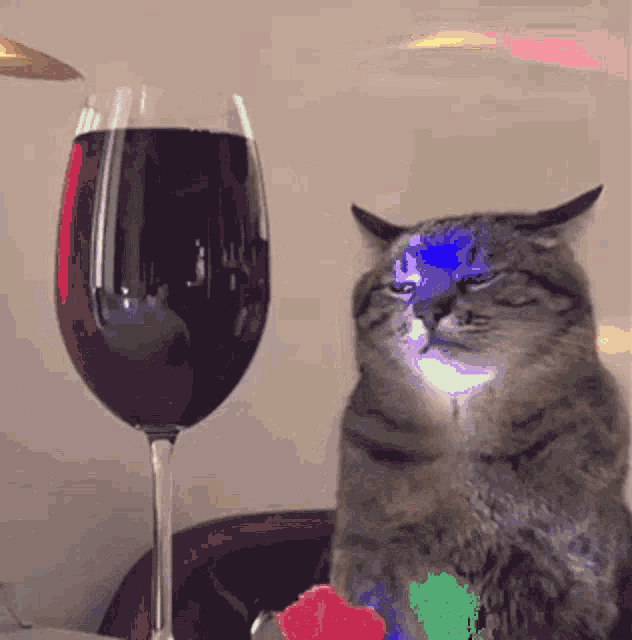

### 2. EDA и описание распределений

Начнём с среднего, медианы, дисперсии, стандартного отклонения, квартилей и асимметрии. Выборочная дисперсия вычисляется с поправкой Бесселя (`ddof=1`):

$$\bar x=\frac{1}{n}\sum_{i=1}^n x_i,\qquad s^2=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2.$$

Гистограммы покажут форму распределения, а Q-Q графики и тест Д’Агостино-Пирсона помогут проверить нормальность. Поскольку наблюдений много, даже небольшие отклонения могут оказаться статистически значимыми.

**Сначала посмотрим на сами данные.** Считаем основные статистики `alcohol` отдельно для красного и белого вина, затем строим гистограммы. Пунктирная линия отмечает среднее: по ней удобно сравнивать положение распределений.

,Красное,Белое
n,1599.0000,4898.0000
Среднее,10.4230,10.5143
Медиана,10.2000,10.4000
Дисперсия,1.1356,1.5144
СКО,1.0657,1.2306
Минимум,8.4000,8.0000
Q1,9.5000,9.5000
Q3,11.1000,11.4000
Максимум,14.9000,14.2000
Асимметрия,0.8608,0.4873


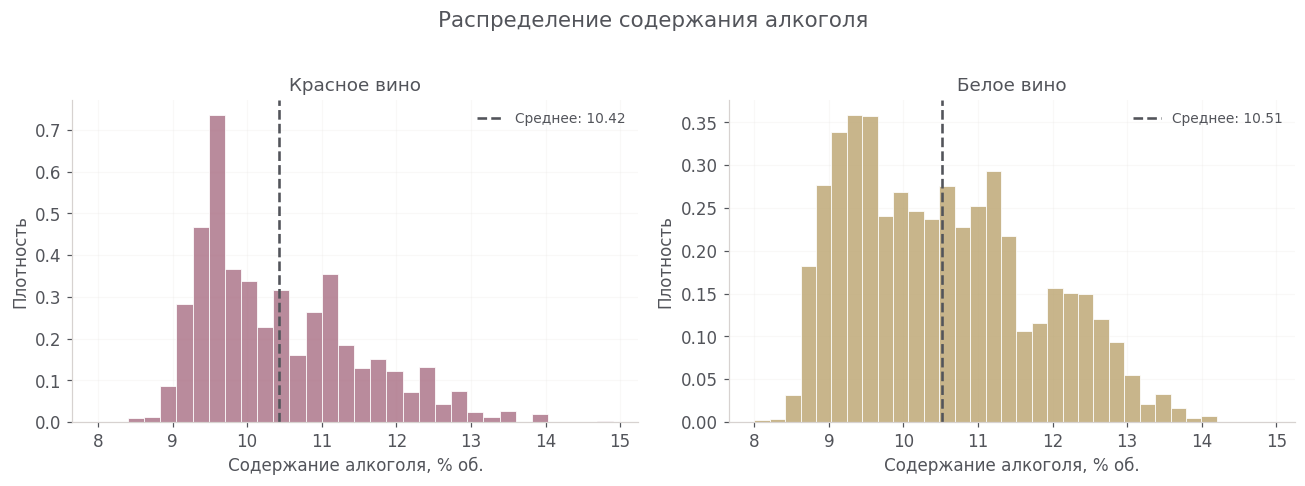

In [22]:
# Собираем статистики в одну таблицу для наглядного сравнения.
def summary(x):
    return pd.Series({
        'n': len(x), 'Среднее': x.mean(), 'Медиана': x.median(),
        'Дисперсия': x.var(ddof=1), 'СКО': x.std(ddof=1),
        'Минимум': x.min(), 'Q1': x.quantile(.25),
        'Q3': x.quantile(.75), 'Максимум': x.max(),
        'Асимметрия': x.skew(), 'Эксцесс': x.kurt()
    })

display(pd.DataFrame({'Красное': summary(red.alcohol),
                      'Белое': summary(white.alcohol)}).round(4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), sharex=True)
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    ax.hist(df.alcohol, bins=30, density=True, color=color,
            alpha=.78, edgecolor='white', linewidth=.65)
    ax.axvline(df.alcohol.mean(), color=DARK, ls='--', lw=1.7,
               label=f'Среднее: {df.alcohol.mean():.2f}')
    ax.set(title=f'{name} вино', xlabel='Содержание алкоголя, % об.',
           ylabel='Плотность')
    ax.legend(frameon=False, fontsize=9)
    ax.set_axisbelow(True)
finish(fig, 'Распределение содержания алкоголя')

**Насколько распределение похоже на нормальное?** На Q-Q графике точки при нормальности должны располагаться примерно вдоль прямой. Дополнительно проверяем это критерием Д’Агостино-Пирсона при уровне значимости 0,05.

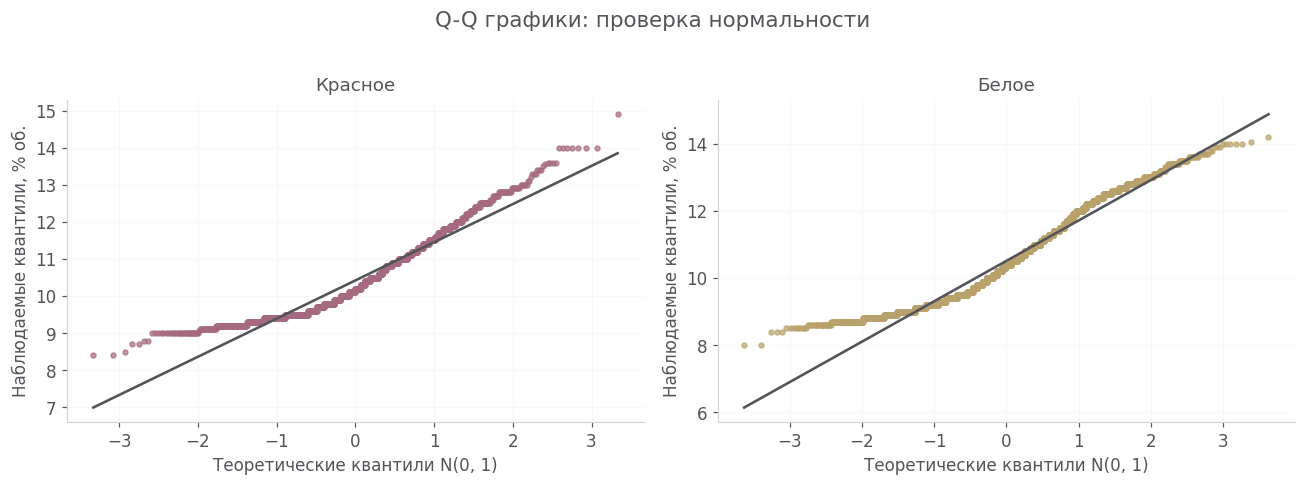

,Тип вина,K²,p-value,"Решение (α = 0,05)"
0,Красное,154.178070,3.316329e-34,H₀ отвергается
1,Белое,430.318952,3.609332e-94,H₀ отвергается


In [23]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
rows = []
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    # Q-Q сравнивает квантили данных с квантилями нормальной модели.
    stats.probplot(df.alcohol, dist='norm', plot=ax)
    ax.get_lines()[0].set(color=color, markersize=3.2, alpha=.7)
    ax.get_lines()[1].set(color=DARK, linewidth=1.7)
    ax.set(title=name, xlabel='Теоретические квантили N(0, 1)',
           ylabel='Наблюдаемые квантили, % об.')
    test = stats.normaltest(df.alcohol)
    rows.append((name, test.statistic, test.pvalue,
                 'H₀ отвергается' if test.pvalue < .05 else 'Нет оснований отвергнуть H₀'))
finish(fig, 'Q-Q графики: проверка нормальности')
display(pd.DataFrame(rows, columns=['Тип вина', 'K²', 'p-value', 'Решение (α = 0,05)']))

### Теоретические модели и критерий AIC

Поскольку `alcohol` положителен и имеет правостороннюю асимметрию, сравним три семейства распределений:

- **Нормальное:** $f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp[-(x-\mu)^2/(2\sigma^2)]$.
- **Логнормальное:** $f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp[-(\ln x-\mu)^2/(2\sigma^2)]$, $x>0$.
- **Гамма:** $f(x)=\frac{x^{a-1}e^{-x/\theta}}{\Gamma(a)\theta^a}$, $x>0$.

$\mu,\sigma$ - параметры нормальной модели (для логнормальной - параметры логарифма величины), $a$ - параметр формы гамма-распределения, $\theta$ - масштаб. Для двух положительных семейств фиксируем `loc=0`.

Сравнение проводим по $\mathrm{AIC}=2k-2\ln L$: чем меньше AIC, тем лучше компромисс между правдоподобием и сложностью **среди рассмотренных моделей**. При этом минимальный AIC не означает, что распределение точно описывает все данные.

Во всех трёх моделях оцениваются два свободных параметра. Фиксированный `loc=0` в штраф AIC не входит.

**Попробуем подобрать распределение.** Для каждого типа вина отдельно оцениваем параметры трёх моделей и сравниваем AIC. Выясняем, какая из предложенных формул лучше согласуется с данными.

In [24]:
models = {'Нормальное': stats.norm,
          'Логнормальное': stats.lognorm,
          'Гамма': stats.gamma}
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    for label, dist in models.items():
        # Параметры подгоняем отдельно для каждого типа вина.
        kw = {'floc': 0} if label != 'Нормальное' else {}
        params = dist.fit(x, **kw)
        aic = 2 * 2 - 2 * np.sum(dist.logpdf(x, *params))
        rows.append((name, label, aic))
aic_df = pd.DataFrame(rows, columns=['Тип вина', 'Распределение', 'AIC'])
display(aic_df.pivot(index='Распределение', columns='Тип вина', values='AIC').round(2))
print('Лучшая модель среди рассмотренных по AIC:')
display(aic_df.loc[aic_df.groupby('Тип вина')['AIC'].idxmin()].round(2))

Тип вина,Белое,Красное
Распределение,,
Гамма,15764.32,4658.60
Логнормальное,15700.50,4621.90
Нормальное,15935.77,4744.16


Лучшая модель среди рассмотренных по AIC:


,Тип вина,Распределение,AIC
4,Белое,Логнормальное,15700.5
1,Красное,Логнормальное,4621.9


### 3. Масштабирование признака

Проверим два способа приведения `alcohol` к единому масштабу:

$$x_{\mathrm{MinMax}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}},\qquad z=\frac{x-\bar x}{s}.$$

Первое преобразование переводит наблюдения в интервал $[0,1]$, второе даёт среднее около нуля и СКО около единицы. Здесь считаем параметры отдельно для красного и белого вина **только для описательного сравнения** (в kNN масштабирование будет настроено только по обучающим данным).

**Проверим масштабирование на практике.** После Min-Max все значения должны оказаться между 0 и 1, а после Z-score среднее станет близким к нулю. Выводим статистики для численной проверки.

In [25]:
# Смотрим, как изменились среднее, разброс и границы после преобразования.
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    variants = {
        'Исходные': x,
        'Min-Max': (x - x.min()) / (x.max() - x.min()),
        'Z-score': (x - x.mean()) / x.std(ddof=1)
    }
    for method, values in variants.items():
        rows.append((name, method, values.mean(), values.std(ddof=1),
                     values.min(), values.max()))
display(pd.DataFrame(rows, columns=[
    'Тип вина', 'Метод', 'Среднее', 'СКО', 'Минимум', 'Максимум'
]).round(4))

,Тип вина,Метод,Среднее,СКО,Минимум,Максимум
0,Красное,Исходные,10.4230,1.0657,8.4000,14.9000
1,Красное,Min-Max,0.3112,0.1639,0.0000,1.0000
2,Красное,Z-score,0.0000,1.0000,-1.8983,4.2011
3,Белое,Исходные,10.5143,1.2306,8.0000,14.2000
4,Белое,Min-Max,0.4055,0.1985,0.0000,1.0000
5,Белое,Z-score,-0.0000,1.0000,-2.0431,2.9950


### 4. Выборки и состоятельность среднего

В рамках нашего эксперимента все строки каждого датасета считаем **условной генеральной совокупностью**. Сравниваем два способа отбора по индексам: с возвращением (индекс может повториться) и без возвращения (каждый индекс выбирается не более одного раза). Одинаковые по значениям строки при этом допустимы.

Для независимого отбора с возвращением $\mathrm{Var}(\bar X_n)=\sigma^2/n$. При простом случайном отборе без возвращения из конечной совокупности из $N$ элементов:

$$\mathrm{Var}(\bar X_n)=\frac{\sigma^2}{n}\frac{N-n}{N-1},$$

где $\sigma^2$ - дисперсия конечной совокупности с делителем $N$. При увеличении $n$ ожидаем уменьшение ошибки оценки среднего. Проверим это повторным моделированием выборок и расчётом RMSE.

**Делаем первые случайные выборки.** Берём по 100 значений двумя способами и сравниваем выборочные средние с полным датасетом.

In [26]:
# Фиксируем генератор (при повторном запуске получим те же выборки).
rng = np.random.default_rng(42)
rows = []
for name, df in [('Красное', red), ('Белое', white)]:
    x = df.alcohol.to_numpy()
    for replace, label in [(False, 'Без возвращения'), (True, 'С возвращением')]:
        sample = rng.choice(x, size=100, replace=replace)
        rows.append((name, label, len(x), len(sample), x.mean(),
                     sample.mean(), x.var(ddof=0), sample.var(ddof=1), np.median(x), np.median(sample)))
display(pd.DataFrame(rows, columns=[
    'Тип вина', 'Метод', 'N', 'n', 'Среднее генеральной',
    'Среднее выборки', 'Дисперсия генеральной', 'Дисперсия выборки', 'Медиана генеральной', 'Медиана выборки'
]).round(4))

,Тип вина,Метод,N,n,Среднее генеральной,Среднее выборки,Дисперсия генеральной,Дисперсия выборки,Медиана генеральной,Медиана выборки
0,Красное,Без возвращения,1599,100,10.4230,10.5465,1.1349,1.2036,10.2,10.40
1,Красное,С возвращением,1599,100,10.4230,10.6190,1.1349,1.1335,10.2,10.45
2,Белое,Без возвращения,4898,100,10.5143,10.5164,1.5141,1.5585,10.4,10.40
3,Белое,С возвращением,4898,100,10.5143,10.5209,1.5141,1.3653,10.4,10.40


**Повторяем эксперимент.** Для каждого размера выборки многократно оцениваем среднее и считаем RMSE относительно среднего полного датасета. На графике будет видно, как уменьшается ошибка.

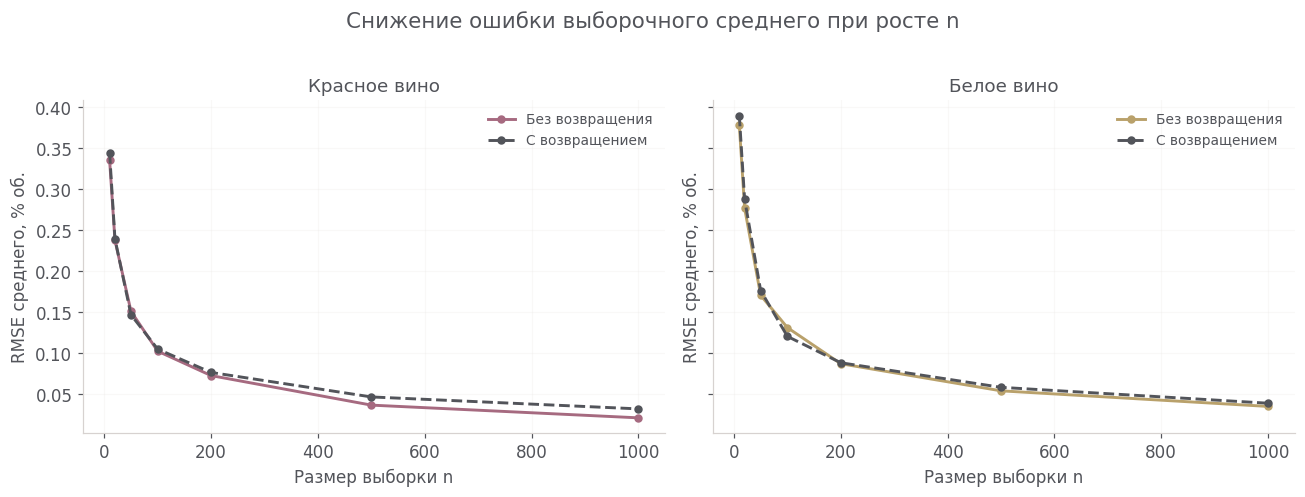

,Тип,Метод,n,Смещение,SD,RMSE,SE теория
0,Красное,Без возвращения,10,-0.0195,0.3353,0.3355,0.3359
3,Красное,Без возвращения,100,-0.0018,0.1025,0.1024,0.1032
6,Красное,Без возвращения,1000,-0.0004,0.0211,0.0211,0.0206
7,Красное,С возвращением,10,0.0096,0.3445,0.3442,0.3369
10,Красное,С возвращением,100,0.0038,0.1050,0.1049,0.1065
13,Красное,С возвращением,1000,-0.0036,0.0318,0.0320,0.0337
14,Белое,Без возвращения,10,0.0178,0.3784,0.3783,0.3888
17,Белое,Без возвращения,100,-0.0056,0.1312,0.1312,0.1218
20,Белое,Без возвращения,1000,0.0003,0.0350,0.0350,0.0347
21,Белое,С возвращением,10,0.0057,0.3903,0.3899,0.3891


In [27]:
sizes = np.array([10, 20, 50, 100, 200, 500, 1000])
B = 400  # число повторных выборок для каждого размера
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
rows = []
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    x = df.alcohol.to_numpy()
    mu = x.mean()  # известное среднее нашей условной генеральной совокупности
    for replace, label, style in [
        (False, 'Без возвращения', '-'), (True, 'С возвращением', '--')
    ]:
        rmse = []
        for size in sizes:
            estimates = np.array([
                rng.choice(x, size=size, replace=replace).mean()
                for _ in range(B)
            ])
            error = np.sqrt(np.mean((estimates - mu) ** 2))
            rmse.append(error)
            se = np.sqrt(x.var(ddof=0) / size * (1 if replace else (len(x)-size)/(len(x)-1)))
            rows.append((name, label, size, estimates.mean()-mu, estimates.std(ddof=1), error, se))
        ax.plot(sizes, rmse, style, marker='o', markersize=4.5,
                linewidth=1.9, color=color if not replace else DARK,
                label=label)
    ax.set(title=f'{name} вино', xlabel='Размер выборки n',
           ylabel='RMSE среднего, % об.')
    ax.legend(frameon=False, fontsize=9)
    ax.set_axisbelow(True)
finish(fig, 'Снижение ошибки выборочного среднего при росте n')
consistency = pd.DataFrame(rows, columns=['Тип', 'Метод', 'n', 'Смещение', 'SD', 'RMSE', 'SE теория'])
display(consistency[consistency.n.isin([10, 100, 1000])].round(4))

### 5. Связь содержания алкоголя с качеством

Проверяем двусторонние гипотезы об отсутствии корреляции:

$$H_0:\rho=0,\qquad H_1:\rho\ne0.$$

Коэффициент **Пирсона** оценивает линейную связь, **Спирмена** - монотонную ранговую. Для каждого используем соответствующий статистический тест и уровень значимости $\alpha=0{,}05$. Малое p-value говорит против отсутствия соответствующей корреляции, но не доказывает причинное влияние алкоголя на качество.

**Теперь проверим связь с качеством.** Рассчитываем корреляции Пирсона и Спирмена, их p-value и строим графики `alcohol`-`quality`. Корреляция показывает статистическую связь, но сама по себе не доказывает причинность.

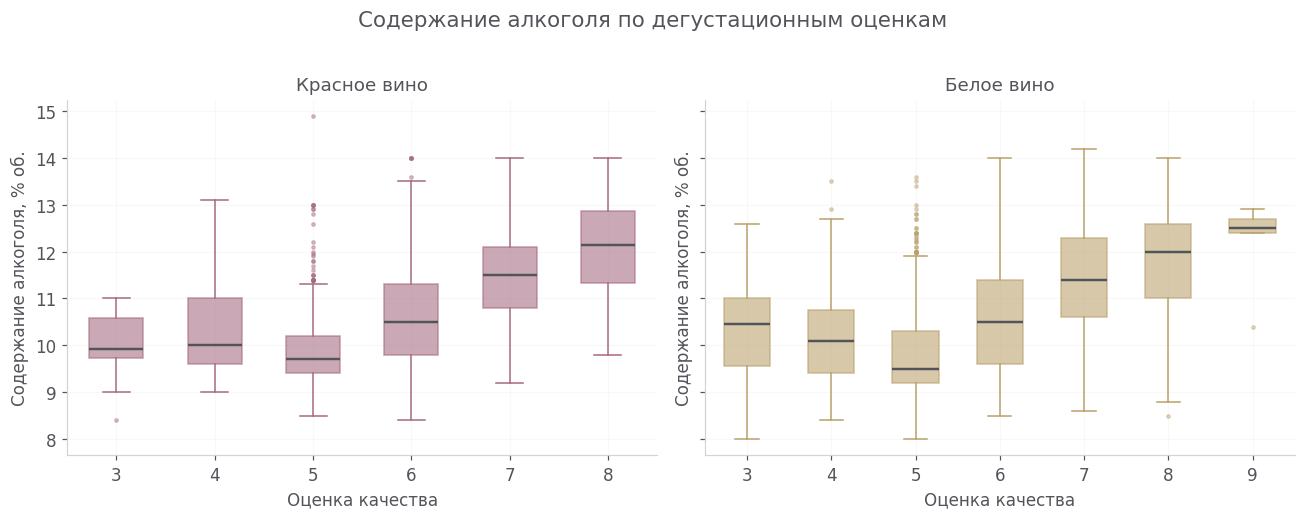

,Тип вина,Пирсон r,p Пирсон,Спирмен ρ,p Спирмен
0,Красное,0.476166,2.831477e-91,0.478532,2.726838e-92
1,Белое,0.435575,5.614770e-226,0.440369,1.659196e-231


In [28]:
# Считаем две корреляции: линейную (Пирсон) и ранговую (Спирмен).
rows = []
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (name, df, color) in zip(axs, [
    ('Красное', red, PINK), ('Белое', white, GOLD)
]):
    pearson = stats.pearsonr(df.alcohol, df.quality)
    spearman = stats.spearmanr(df.alcohol, df.quality)
    rows.append((name, pearson.statistic, pearson.pvalue,
                 spearman.statistic, spearman.pvalue))
    scores = sorted(df.quality.unique())
    groups = [df.loc[df.quality == q, 'alcohol'].values for q in scores]
    bp = ax.boxplot(groups, positions=scores, patch_artist=True, widths=.55,
                    medianprops={'color': DARK, 'linewidth': 1.6},
                    boxprops={'color': color, 'linewidth': 1.1},
                    whiskerprops={'color': color}, capprops={'color': color},
                    flierprops={'marker': 'o', 'markersize': 2.2,
                                'markerfacecolor': color, 'markeredgecolor': color,
                                'alpha': .4})
    for patch in bp['boxes']:
        patch.set(facecolor=color, alpha=.58)
    ax.set(title=f'{name} вино', xlabel='Оценка качества',
           ylabel='Содержание алкоголя, % об.', xticks=scores)
    ax.set_axisbelow(True)
finish(fig, 'Содержание алкоголя по дегустационным оценкам')
corr_df = pd.DataFrame(rows, columns=[
    'Тип вина', 'Пирсон r', 'p Пирсон', 'Спирмен ρ', 'p Спирмен'
])
display(corr_df)

### 6. Нормы и геометрия пространства признаков

Для двух векторов $x,y\in\mathbb R^d$ расстояния задаются нормами разности:

$$d_1(x,y)=\sum_i|x_i-y_i|,\qquad d_2(x,y)=\sqrt{\sum_i(x_i-y_i)^2},\qquad d_\infty(x,y)=\max_i|x_i-y_i|.$$

В двумерном случае единичные линии уровня имеют форму **ромба, окружности и квадрата**.

**Переходим от статистики к геометрии.** Записываем три функции расстояния и строим линии уровня: ромб для L1, окружность для L2 и квадрат для L∞. Так становится понятнее, почему выбор метрики влияет на соседей.

Проверка на векторах (1, 2) и (4, 6): {'L1': 7.0, 'L2': 5.0, 'Linf': 4.0}


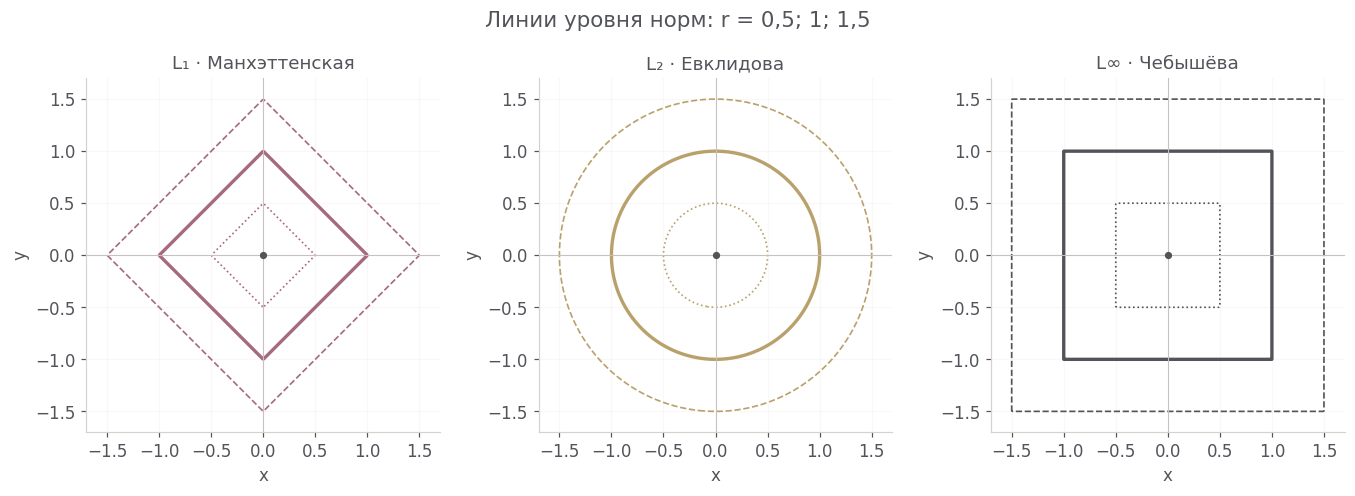

In [29]:
def distance(a, b, metric='L2'):
    """Расстояние между двумя векторами без готовых функций метрик."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if a.shape != b.shape or a.size == 0:
        raise ValueError('Нужны непустые векторы одинаковой формы')
    delta = np.abs(a - b)
    if metric == 'L1':
        return float(delta.sum())
    if metric == 'L2':
        return float(np.sqrt((delta ** 2).sum()))
    if metric == 'Linf':
        return float(delta.max())
    raise ValueError('Неизвестная метрика')

print('Проверка на векторах (1, 2) и (4, 6):',
      {m: distance([1, 2], [4, 6], m) for m in ['L1', 'L2', 'Linf']})

# Строим линии уровней 0.5, 1 и 1.5, чтобы сравнить геометрию норм.
coords = np.linspace(-1.7, 1.7, 350)
XX, YY = np.meshgrid(coords, coords)
levels = [0.5, 1, 1.5]
fields = [np.abs(XX) + np.abs(YY),
          np.sqrt(XX ** 2 + YY ** 2),
          np.maximum(np.abs(XX), np.abs(YY))]
fig, axs = plt.subplots(1, 3, figsize=(12.5, 4.2))
for ax, field, title, color in zip(
    axs, fields, ['L₁ · Манхэттенская', 'L₂ · Евклидова', 'L∞ · Чебышёва'],
    [PINK, GOLD, DARK]
):
    ax.contour(XX, YY, field, levels=levels, colors=[color],
               linewidths=[1.1, 2.2, 1.1], linestyles=['dotted', 'solid', 'dashed'])
    ax.scatter([0], [0], color=DARK, s=14, zorder=4)
    ax.axhline(0, color='#C7C2C0', linewidth=.7)
    ax.axvline(0, color='#C7C2C0', linewidth=.7)
    ax.set(title=title, xlabel='x', ylabel='y', xlim=(-1.7, 1.7),
           ylim=(-1.7, 1.7), aspect='equal')
    ax.set_axisbelow(True)
finish(fig, 'Линии уровня норм: r = 0,5; 1; 1,5')

### 7. kNN: реализация и проверка на данных вина

Прогнозируем `quality` по **11 физико-химическим признакам и типу вина** (12 признаков). Целевая оценка не включается в признаки. Сначала выделяем тестовую выборку, затем из оставшихся данных - валидационную. Одинаковые векторы признаков (с учётом типа вина) относятся только к одной части.

Для вычисления расстояний важно привести признаки к сопоставимому масштабу. Среднее и СКО для стандартизации определяем **только по обучающей части**, иначе в обучение попадёт информация из валидации или теста.

**Готовим данные для проверки kNN.** Разделяем наблюдения на обучение, валидацию и тест. Одинаковые химические профили не должны оказаться в разных частях; параметры стандартизации вычисляем только на обучении.

In [30]:
# Подготавливаем данные для модели.
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

# sklearn используем для разбиения и оценочных метрик, но не для самого kNN.
full = pd.concat([red.assign(wine_type=0),
                  white.assign(wine_type=1)], ignore_index=True)
features = [c for c in full.columns if c != 'quality']
X = full[features].to_numpy(dtype=float)
y = full.quality.to_numpy(dtype=int)

# Одинаковые химические профили должны попасть в одну группу.
groups = pd.util.hash_pandas_object(full[features], index=False).to_numpy()
gss = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=42)
trainval_idx, test_idx = next(gss.split(X, y, groups))
gss_val = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=43)
a_idx, b_idx = next(gss_val.split(
    X[trainval_idx], y[trainval_idx], groups[trainval_idx]
))
train_idx, val_idx = trainval_idx[a_idx], trainval_idx[b_idx]
assert not (set(groups[train_idx]) & set(groups[val_idx]))
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[val_idx]) & set(groups[test_idx]))

scaler = StandardScaler().fit(X[train_idx])
Xtr, Xv, Xt = (scaler.transform(X[idx]) for idx in
               [train_idx, val_idx, test_idx])
ytr, yv, yt = y[train_idx], y[val_idx], y[test_idx]
print('Train / Validation / Test:', len(ytr), len(yv), len(yt))
print('Пересечения одинаковых профилей: отсутствуют')

Train / Validation / Test: 4182 1022 1293
Пересечения одинаковых профилей: отсутствуют


### Устройство классификатора

Для каждого образца вычисляем расстояние до всех объектов обучения, сортируем индексы по расстоянию и берём первые $k$. Прогноз - наиболее частая оценка среди этих соседей:

$$\hat y(x)=\arg\max_c\sum_{i\in N_k(x)}\mathbf1(y_i=c).$$

Если несколько оценок получили одинаковое число голосов, выбираем ту, у которой **меньше суммарное расстояние** до соседей соответствующего класса; при полном равенстве - меньшую оценку. Сортировка с фиксированным правилом устраняет неоднозначность при равных расстояниях.

**Пишем kNN.** Для каждого нового образца находим расстояния до обучающих, выбираем ближайшие `k` объектов и голосуем за оценку качества. `assert` в конце проверяют базовую логику.

In [31]:
def knn_predict(X_train, y_train, X_query, k=15, metric='L1', batch_size=80):
    """Собственный kNN: расстояния, ближайшие соседи, голосование."""
    if not 1 <= k <= len(X_train):
        raise ValueError('k должно быть от 1 до числа обучающих объектов')
    result = []
    for start in range(0, len(X_query), batch_size):
        # Пакеты позволяют не хранить огромную матрицу расстояний сразу.
        Q = X_query[start:start + batch_size]
        delta = np.abs(Q[:, None, :] - X_train[None, :, :])
        if metric == 'L1':
            dist = delta.sum(axis=2)
        elif metric == 'L2':
            dist = np.sqrt((delta ** 2).sum(axis=2))
        elif metric == 'Linf':
            dist = delta.max(axis=2)
        else:
            raise ValueError('Неизвестная метрика')
        for distances in dist:
            ix = np.argsort(distances, kind='stable')[:k]
            labels = y_train[ix]
            classes, counts = np.unique(labels, return_counts=True)
            tied = classes[counts == counts.max()]
            if len(tied) == 1:
                result.append(tied[0])
            else:
                result.append(min(
                    tied, key=lambda c: (distances[ix[labels == c]].sum(), c)
                ))
    return np.asarray(result, dtype=int)

# Проверка на маленьком примере, где ответ можно получить вручную.
assert distance([0, 0], [3, 4], 'L2') == 5
assert knn_predict(np.array([[0.], [1.], [10.]]),
                   np.array([1, 1, 2]), np.array([[.2]]), k=1)[0] == 1
print('Проверки реализации пройдены')

Проверки реализации пройдены


### Выбор метрики и числа соседей

Сравниваем $L_1$, $L_2$, $L_\infty$ при $k\in\{1,5,11,15,21\}$ на **валидационной** выборке. Основной критерий - Accuracy; при равенстве выбираем меньшую MAE. После выбора гиперпараметров один раз оцениваем модель на независимом тесте (так тест не участвует в настройке).

$$\mathrm{Accuracy}=\frac{1}{n}\sum_i\mathbf1(\hat y_i=y_i),\qquad
\mathrm{MAE}=\frac{1}{n}\sum_i|\hat y_i-y_i|.$$

**Подбираем настройки без подсматривания в тест.** Сравниваем три метрики и несколько значений `k` на валидационной части. На графике отмечаем лучшую комбинацию, которую затем будем проверять отдельно.

,Метрика,k,Accuracy,MAE
0,L1,1,0.4795,0.6370
1,L1,5,0.4980,0.5763
2,L1,11,0.5294,0.5382
3,L1,15,0.5294,0.5391
4,L1,21,0.5333,0.5245
5,L2,1,0.4560,0.6575
6,L2,5,0.5049,0.5705
7,L2,11,0.5323,0.5294
8,L2,15,0.5440,0.5147
9,L2,21,0.5470,0.5127


Лучший вариант: L2, k=21, Accuracy=0.5470, MAE=0.5127


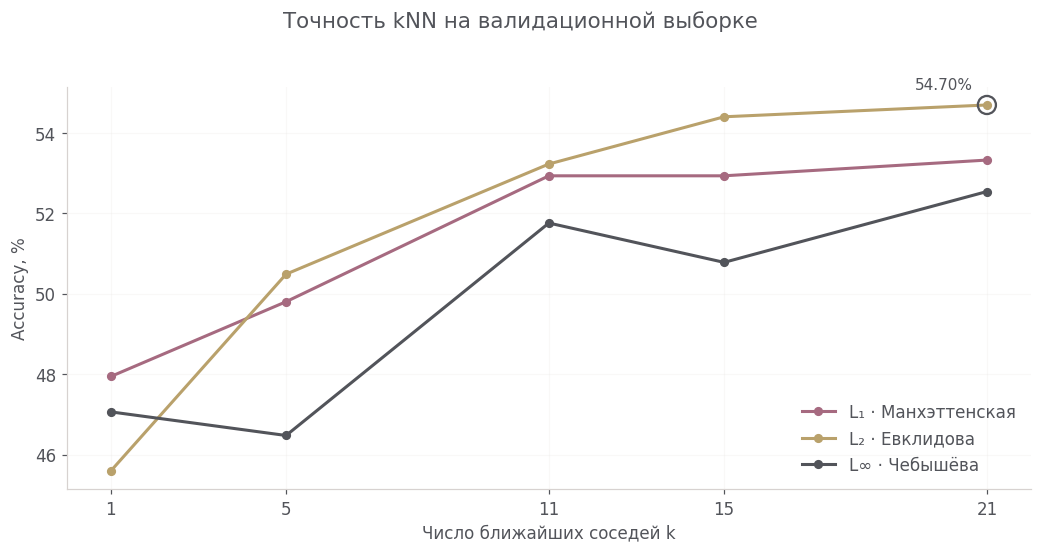

In [32]:
# Сравниваем настройки только на валидации - тест пока не трогаем.
rows = []
for metric in ['L1', 'L2', 'Linf']:
    for k in [1, 5, 11, 15, 21]:
        pred = knn_predict(Xtr, ytr, Xv, k=k, metric=metric)
        rows.append((metric, k, accuracy_score(yv, pred),
                     mean_absolute_error(yv, pred)))
results = pd.DataFrame(rows, columns=['Метрика', 'k', 'Accuracy', 'MAE'])
display(results.round(4))
best = results.sort_values(['Accuracy', 'MAE'],
                           ascending=[False, True]).iloc[0]
print(f'Лучший вариант: {best["Метрика"]}, k={int(best.k)}, '
      f'Accuracy={best.Accuracy:.4f}, MAE={best.MAE:.4f}')

fig, ax = plt.subplots(figsize=(9.6, 4.9))
for metric, color, label in [
    ('L1', PINK, 'L₁ · Манхэттенская'),
    ('L2', GOLD, 'L₂ · Евклидова'),
    ('Linf', DARK, 'L∞ · Чебышёва')
]:
    part = results[results['Метрика'] == metric]
    ax.plot(part.k, part.Accuracy * 100, marker='o', markersize=5,
            linewidth=2, color=color, label=label)
ax.scatter(best.k, best.Accuracy * 100, s=140, facecolors='none',
           edgecolors=DARK, linewidths=1.5, zorder=5)
ax.annotate(f'{best.Accuracy * 100:.2f}%',
            (best.k, best.Accuracy * 100), xytext=(-47, 10),
            textcoords='offset points', fontsize=10)
ax.set(xlabel='Число ближайших соседей k', ylabel='Accuracy, %',
       xticks=[1, 5, 11, 15, 21])
ax.legend(frameon=False, loc='lower right')
ax.set_axisbelow(True)
finish(fig, 'Точность kNN на валидационной выборке')

**Последняя проверка - на отложенном тесте.** Сравниваем наш kNN с простым ориентиром: моделью, которая всегда выбирает наиболее частую оценку. Помимо точных попаданий считаем MAE, RMSE и долю ошибок не более одного балла.

In [33]:
# Финальная оценка: гиперпараметры уже зафиксированы на валидации.
pred_test = knn_predict(Xtr, ytr, Xt, int(best.k), str(best['Метрика']))
majority = pd.Series(ytr).mode().iloc[0]
baseline = np.full_like(yt, majority)
comparison = pd.DataFrame([
    ('kNN', accuracy_score(yt, pred_test),
     mean_absolute_error(yt, pred_test),
     np.sqrt(mean_squared_error(yt, pred_test))),
    ('Частый класс', accuracy_score(yt, baseline),
     mean_absolute_error(yt, baseline),
     np.sqrt(mean_squared_error(yt, baseline)))
], columns=['Модель', 'Accuracy', 'MAE', 'RMSE'])
display(comparison.round(4))
within_one = np.mean(np.abs(yt - pred_test) <= 1)
print(f'Доля прогнозов с ошибкой не более 1 балла: {within_one:.2%}')

,Модель,Accuracy,MAE,RMSE
0,kNN,0.5414,0.5035,0.7722
1,Частый класс,0.4501,0.6141,0.8688


Доля прогнозов с ошибкой не более 1 балла: 95.67%


### Итоговые выводы

Средняя крепость красного вина составляет 10,42% об., белого 10,51% об.
Нормальная модель не согласуется с данными по тесту Д'Агостино-Пирсона.
Среди трёх проверенных семейств минимальный AIC у логнормального; это относительное сравнение моделей.
Z-стандартизация меняет масштаб, но не делает данные нормальными.

RMSE среднего снижается при росте выборки. Корреляция Пирсона с качеством положительна:
0,4762 у красного и 0,4356 у белого вина. Причинное влияние этим не установлено.

В дополнительной задаче классификации используются 12 признаков, включая тип вина.
Выбранные параметры и результат на test напечатаны выше. Это отдельный эксперимент:
его нельзя смешивать с регрессией по одному alcohol во втором спринте.

<div align="right">
Продолжение следует...
</div>

<a id="rv03"></a>

## Random Variable 03 (volatile_acidity)

Источник раздела: [03_volatile_acidity.ipynb](sprint1/03_volatile_acidity.ipynb).

### Description

Летучая кислотность измеряется в г/дм³ в пересчёте на уксусную кислоту.
Случайный эксперимент: равномерно выбрать строку набора и записать её кислотность.
Значение зависит от выбранной пробы; различаются условия производства и измерений.
Для фиксированной строки результат известен. Сложность химии сама по себе не доказывает случайность.

### EDA & Distribution

In [34]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.plotting import use_style
use_style()
import matplotlib.patches as patches
df = load_wines(ROOT / 'data/raw').rename(columns=lambda c: c.replace('_', ' ')).rename(columns={'wine type': 'color'})
print({'rows': len(df), 'missing': int(df.isna().sum().sum()), 'duplicates': int(df.duplicated().sum())})
display(df.head())

{'rows': 6497, 'missing': 0, 'duplicates': 1177}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Описательные статистики volatile acidity:
Среднее:        0.3397
Медиана:        0.2900
Дисперсия:      0.0271
Стд. отклонение:0.1646
Асимметрия:     1.4948
Эксцесс:        2.8223

Тест нормальности D'Agostino-Pearson:
Статистика: 1786.1417
p-value:    0


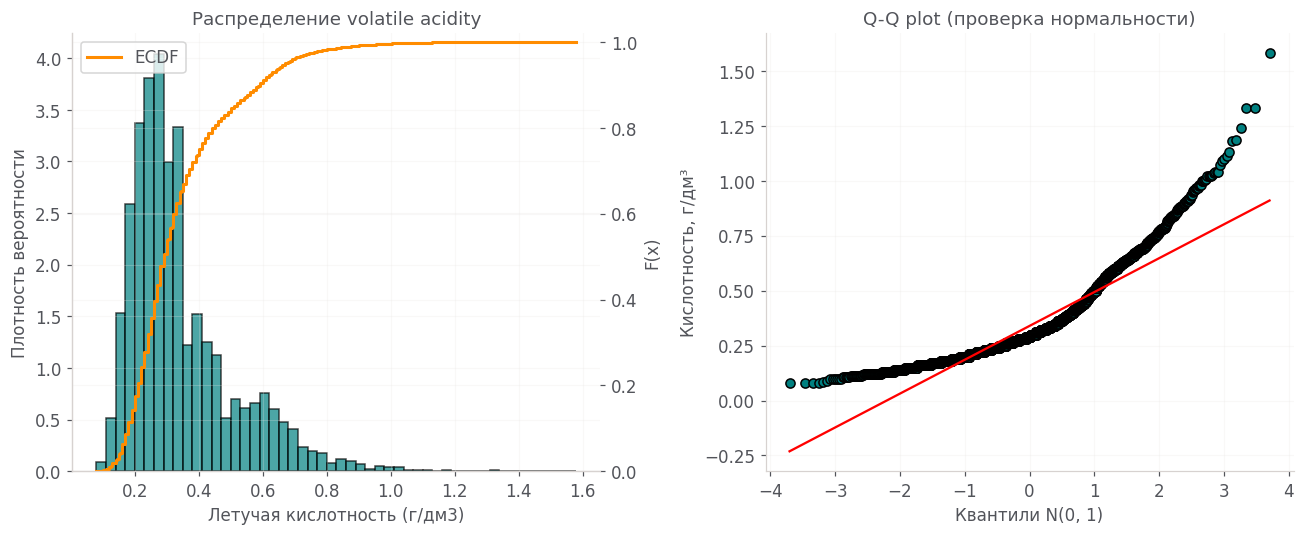

In [35]:
import seaborn as sns
import scipy.stats as stats

va = df['volatile acidity']

print("Описательные статистики volatile acidity:")
print(f"Среднее:        {va.mean():.4f}")
print(f"Медиана:        {va.median():.4f}")
print(f"Дисперсия:      {va.var():.4f}")
print(f"Стд. отклонение:{va.std():.4f}")
print(f"Асимметрия:     {stats.skew(va):.4f}")
print(f"Эксцесс:        {stats.kurtosis(va):.4f}")

normality_test = stats.normaltest(va)
print(f"\nТест нормальности D'Agostino-Pearson:")
print(f"Статистика: {normality_test.statistic:.4f}")
print(f"p-value:    {normality_test.pvalue:.6g}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hist(va, bins=50, density=True, alpha=0.7, color='teal', edgecolor='black')
ax1.set_title("Распределение volatile acidity")
ax1.set_xlabel("Летучая кислотность (г/дм3)")
ax1.set_ylabel("Плотность вероятности")

x_sorted, counts = np.unique(va, return_counts=True)
y_ecdf = np.cumsum(counts) / counts.sum()
ax_ecdf = ax1.twinx()
ax_ecdf.step(x_sorted, y_ecdf, where='post', color='darkorange', linewidth=2, label='ECDF')
ax_ecdf.set_ylabel('F(x)')
ax_ecdf.set_ylim(0, 1.02)
ax_ecdf.legend()

stats.probplot(va, dist="norm", plot=ax2)
ax2.set_title("Q-Q plot (проверка нормальности)")
ax2.set_xlabel("Квантили N(0, 1)")
ax2.set_ylabel("Кислотность, г/дм³")
ax2.get_lines()[0].set_markerfacecolor('teal')
ax2.get_lines()[0].set_markeredgecolor('black')

plt.tight_layout()
plt.show()

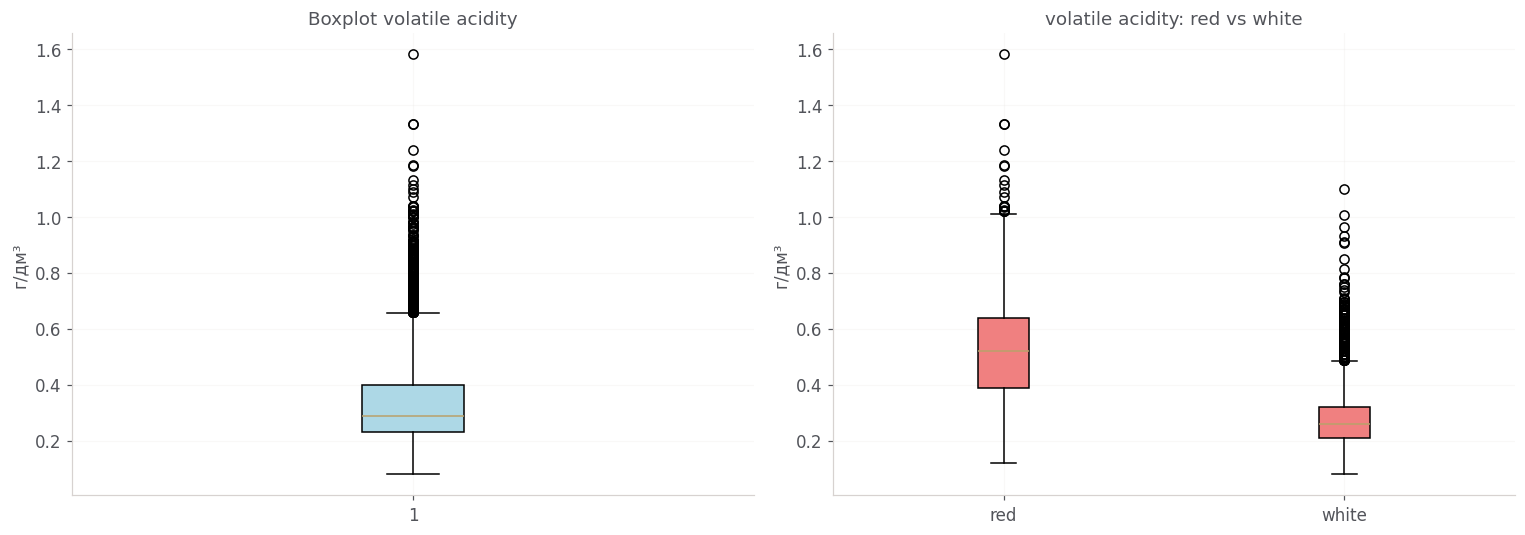

Красные: n=1599, mean=0.5278, median=0.5200
Белые:   n=4898, mean=0.2782, median=0.2600

Mann-Whitney U: U=7059623.5, p-value=0


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot(va, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue'))
axes[0].set_title('Boxplot volatile acidity')
axes[0].set_ylabel('г/дм³')

va_red = df[df['color'] == 'red']['volatile acidity']
va_white = df[df['color'] == 'white']['volatile acidity']
axes[1].boxplot([va_red, va_white], tick_labels=['red', 'white'],
                patch_artist=True,
                boxprops=dict(facecolor='lightcoral'))
axes[1].set_title('volatile acidity: red vs white')
axes[1].set_ylabel('г/дм³')

plt.tight_layout()
plt.show()

print(f"Красные: n={len(va_red)}, mean={va_red.mean():.4f}, median={va_red.median():.4f}")
print(f"Белые:   n={len(va_white)}, mean={va_white.mean():.4f}, median={va_white.median():.4f}")

from scipy.stats import mannwhitneyu
u_stat, p_mw = mannwhitneyu(va_red, va_white, alternative='two-sided')
print(f"\nMann-Whitney U: U={u_stat:.1f}, p-value={p_mw:.6g}")

### Математическая база подобранных распределений

**Логнормальное** (случайная величина $X>0$, если $\ln X \sim \mathcal{N}(\mu, \sigma^2)$):

$$f(x; \mu, \sigma) = \frac{1}{x\sigma\sqrt{2\pi}} \exp\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right)$$

Оценки МП: $\hat\mu = \overline{\ln x}$, $\hat\sigma^2 = \frac{1}{n}\sum (\ln x_i - \hat\mu)^2$. Хвост тяжелее нормального - хорошо подходит для скошенных положительных данных.

**Гамма** (при целом $k$ это сумма $k$ независимых экспоненциальных величин с масштабом $\theta$; в общем случае $k>0$):

$$f(x; k, \theta) = \frac{x^{k-1} e^{-x/\theta}}{\theta^k \Gamma(k)}, \quad x>0$$

Оценки МП через численное решение уравнения для $k$ и $\theta = \bar x/k$. Параметр $k$ (форма) регулирует скошенность, $\theta$ (масштаб) - разброс.

**Выбор модели - критерий Акаике:** $\mathrm{AIC} = 2k - 2\ln \hat L$, штраф за число параметров. У обоих распределений $k=2$, поэтому сравнение по AIC эквивалентно сравнению логарифма правдоподобия.

Lognormal params: (np.float64(0.43901245106918074), 0, np.float64(0.30718848517614583))
  KS stat = 0.0630, AIC = -7592.1
Gamma params:     (5.135907429210994, 0, np.float64(0.06613553775527199))
  KS stat = 0.0943, AIC = -7105.2


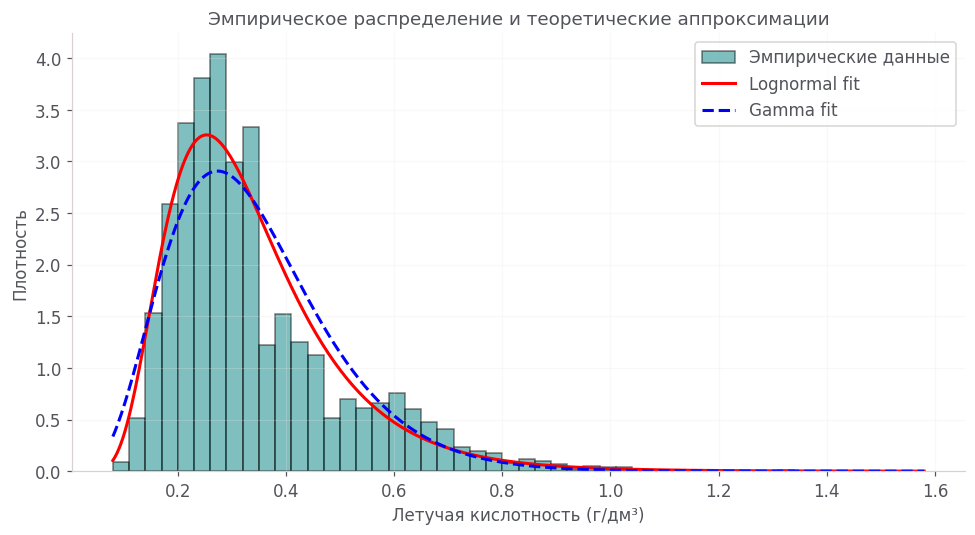

In [37]:
from scipy import stats as sps

va_arr = df['volatile acidity'].values

# Логнормальное (floc=0 - фиксируем нижнюю границу в 0)
ln_params = sps.lognorm.fit(va_arr, floc=0)
ln_ll = np.sum(sps.lognorm.logpdf(va_arr, *ln_params))
ln_aic = 2 * 2 - 2 * ln_ll   # k=2 (s, scale)

# Гамма (floc=0)
gm_params = sps.gamma.fit(va_arr, floc=0)
gm_ll = np.sum(sps.gamma.logpdf(va_arr, *gm_params))
gm_aic = 2 * 2 - 2 * gm_ll

# Расстояние KS описательно: параметры оценены на тех же данных.
ln_ks = sps.kstest(va_arr, 'lognorm', args=ln_params)
gm_ks = sps.kstest(va_arr, 'gamma',  args=gm_params)

print(f"Lognormal params: {ln_params}")
print(f"  KS stat = {ln_ks.statistic:.4f}, AIC = {ln_aic:.1f}")
print(f"Gamma params:     {gm_params}")
print(f"  KS stat = {gm_ks.statistic:.4f}, AIC = {gm_aic:.1f}")

# Наложим обе плотности на гистограмму
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(va_arr, bins=50, density=True, alpha=0.5,
        color='teal', edgecolor='black', label='Эмпирические данные')
x_grid = np.linspace(va_arr.min(), va_arr.max(), 400)
ax.plot(x_grid, sps.lognorm.pdf(x_grid, *ln_params),
        'r-', lw=2, label='Lognormal fit')
ax.plot(x_grid, sps.gamma.pdf(x_grid, *gm_params),
        'b--', lw=2, label='Gamma fit')
ax.set_xlabel('Летучая кислотность (г/дм³)')
ax.set_ylabel('Плотность')
ax.set_title('Эмпирическое распределение и теоретические аппроксимации')
ax.legend()
plt.tight_layout()
plt.show()

### Вывод по распределению

Медианы кислотности красных и белых вин равны 0,52 и 0,26 г/дм³.
Тест Манна-Уитни проверяет $H_0$: распределения в группах одинаковы, против двусторонней альтернативы.
При $\alpha=0{,}05$ гипотеза отвергается. Это не тест равенства средних и не объяснение причины различий.

Логнормальная модель имеет меньший AIC, чем гамма-модель.
Расстояние KS используем только как описательную меру: обычный p-value некорректен после подгонки
параметров по тем же данным. Округление и смешение двух типов вина также ограничивают непрерывные модели.
Для анализа сохраняем эмпирическое распределение.

### Нормализация

Z-нормализация приводит volatile acidity к стандартному масштабу (μ=0, σ=1). Это стандартная процедура перед многомерными методами (PCA, k-NN, линейная регрессия), чувствительными к масштабу признаков. Важно понимать, что z-преобразование - это линейное аффинное преобразование: оно сдвигает и масштабирует, но не меняет форму распределения. Асимметрия и эксцесс остаются теми же, правосторонняя скошенность не изменяется. Для этого нужны нелинейные преобразования (логарифм, Бокс-Кокс). В дальнейшем анализе мы работаем с исходными значениями, поскольку физическая интерпретация (г/дм³ уксусной кислоты) удобнее в исходных единицах; нормализация здесь приведена как демонстрация приведения к стандартному масштабу.

После нормализации: mean = 0.000000, std = 1.000000


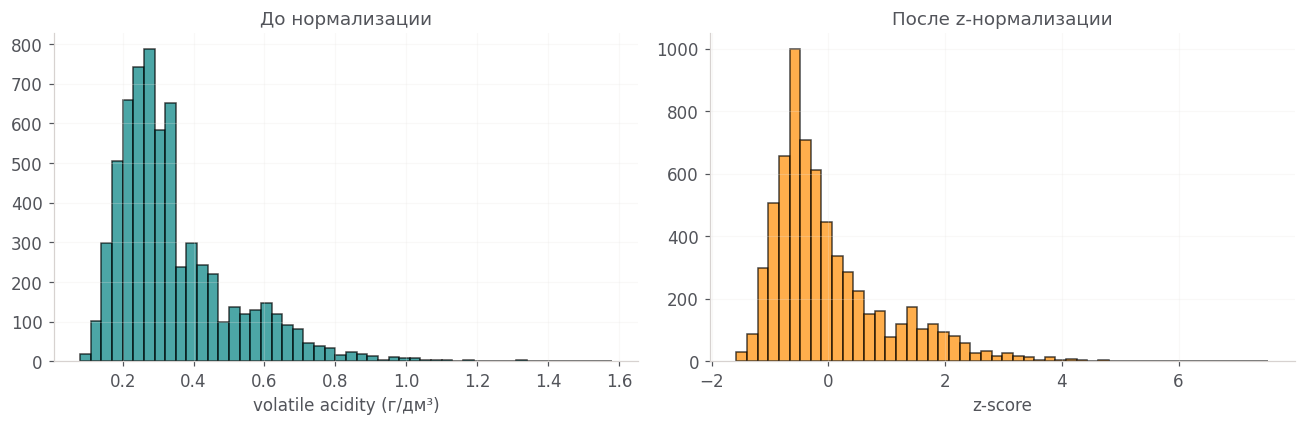

      n  Bias WR  Bias WOR  RMSE WR  RMSE WOR  Mean (with rep)  SD (with rep)  \
0    10   0.0000    0.0010   0.0510    0.0527           0.3397         0.0510   
1    50   0.0003   -0.0008   0.0227    0.0231           0.3400         0.0228   
2   100   0.0004   -0.0001   0.0164    0.0163           0.3401         0.0164   
3   500  -0.0001    0.0001   0.0074    0.0071           0.3396         0.0074   
4  1000  -0.0001    0.0002   0.0054    0.0050           0.3396         0.0054   
5  2000   0.0000    0.0001   0.0037    0.0030           0.3397         0.0037   
6  6497  -0.0000    0.0000   0.0020    0.0000           0.3396         0.0020   

   Mean (without rep)  SD (without rep)  Theoretical SD  Rel. Error (%)  
0              0.3407            0.0527          0.0520          1.3419  
1              0.3389            0.0231          0.0232          0.2706  
2              0.3395            0.0163          0.0163          0.0358  
3              0.3398            0.0071          0.0071

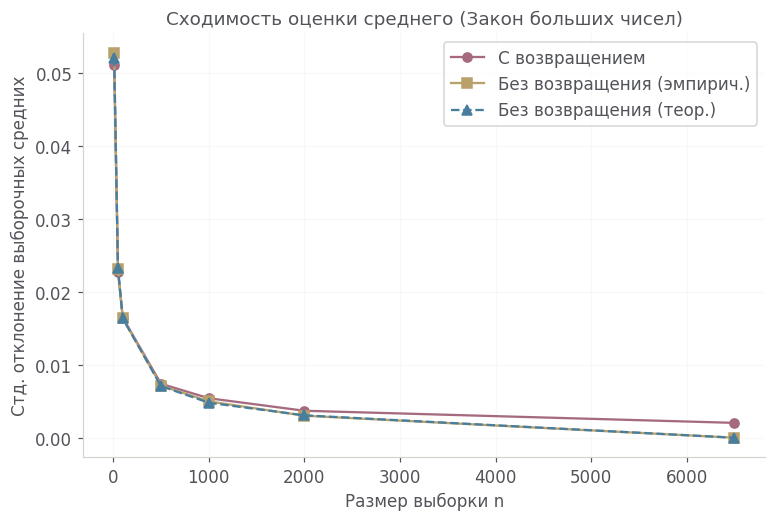


Истинное среднее по совокупности: 0.3397
Максимальная относительная ошибка SD: 3.87%


In [38]:
va_z = (va - va.mean()) / va.std(ddof=1)
print(f"После нормализации: mean = {va_z.mean():.6f}, std = {va_z.std(ddof=1):.6f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(va, bins=50, color='teal', alpha=0.7, edgecolor='black')
axes[0].set_title('До нормализации')
axes[0].set_xlabel('volatile acidity (г/дм³)')

axes[1].hist(va_z, bins=50, color='darkorange', alpha=0.7, edgecolor='black')
axes[1].set_title('После z-нормализации')
axes[1].set_xlabel('z-score')

plt.tight_layout()
plt.show()

pop = va.to_numpy()
pop_mean = pop.mean()
pop_var = pop.var(ddof=0)
N = len(pop)

sizes = [10, 50, 100, 500, 1000, 2000, N]
rows = []
rng = np.random.default_rng(42)

for n in sizes:
    means_with_rep = [rng.choice(pop, size=n, replace=True).mean() for _ in range(1000)]
    means_without_rep = [rng.choice(pop, size=n, replace=False).mean() for _ in range(1000)]

    sd_with = np.std(means_with_rep, ddof=1)
    sd_without = np.std(means_without_rep, ddof=1)
    sd_theor = np.sqrt((pop_var / n) * ((N - n) / (N - 1)))

    rel_error = abs(sd_without - sd_theor) / sd_theor * 100 if sd_theor else np.nan

    rows.append({
        "n": n,
        "Bias WR": np.mean(means_with_rep) - pop_mean,
        "Bias WOR": np.mean(means_without_rep) - pop_mean,
        "RMSE WR": np.sqrt(np.mean((np.array(means_with_rep)-pop_mean)**2)),
        "RMSE WOR": np.sqrt(np.mean((np.array(means_without_rep)-pop_mean)**2)),
        "Mean (with rep)": np.mean(means_with_rep),
        "SD (with rep)": sd_with,
        "Mean (without rep)": np.mean(means_without_rep),
        "SD (without rep)": sd_without,
        "Theoretical SD": sd_theor,
        "Rel. Error (%)": rel_error
    })

est_df = pd.DataFrame(rows)
print(est_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(est_df["n"], est_df["SD (with rep)"], marker='o', label="С возвращением")
plt.plot(est_df["n"], est_df["SD (without rep)"], marker='s', label="Без возвращения (эмпирич.)")
plt.plot(est_df["n"], est_df["Theoretical SD"], marker='^', linestyle='--', label="Без возвращения (теор.)")
plt.xlabel("Размер выборки n")
plt.ylabel("Стд. отклонение выборочных средних")
plt.title("Сходимость оценки среднего (Закон больших чисел)")
plt.legend()
plt.show()

print(f"\nИстинное среднее по совокупности: {pop_mean:.4f}")
print(f"Максимальная относительная ошибка SD: {est_df['Rel. Error (%)'].max():.2f}%")

### Independence & Estimations

Дисперсия среднего при отборе с возвращением равна $\sigma^2/n$,
без возвращения $\sigma^2(N-n)/(n(N-1))$. Здесь $\sigma^2$ имеет делитель $N$.
Смещение, RMSE и разброс средних рассчитаны по 1000 повторам для каждого $n$.
Ошибка снижается при росте выборки. При $n=N$ без возвращения среднее совпадает с генеральным.
Это иллюстрация состоятельности в принятой модели отбора.
При $n=2000$ доля выборки около 31%, поэтому конечную поправку уже нельзя считать малой.

### Sampling

Сравним полный набор и выборки по 500 строк. Совпадение статистик приблизительное;
одна выборка не гарантирует точного описания правого хвоста.

In [39]:
rng_sample = np.random.default_rng(2026)
parts = {'Полный набор': va.to_numpy(),
         'С возвращением': rng_sample.choice(va, 500, replace=True),
         'Без возвращения': rng_sample.choice(va, 500, replace=False)}
display(pd.DataFrame([{'Данные': name, 'n': len(x), 'Среднее': x.mean(),
    'Медиана': np.median(x), 'Дисперсия': x.var(ddof=0 if name == 'Полный набор' else 1)}
    for name, x in parts.items()]).round(5))

,Данные,n,Среднее,Медиана,Дисперсия
0,Полный набор,6497,0.33967,0.29,0.02710
1,С возвращением,500,0.33482,0.28,0.02484
2,Без возвращения,500,0.33398,0.30,0.02345


Дисперсии всех числовых признаков (топ-5):


,0
total sulfur dioxide,3194.72
free sulfur dioxide,315.04
residual sugar,22.64
fixed acidity,1.68
alcohol,1.42


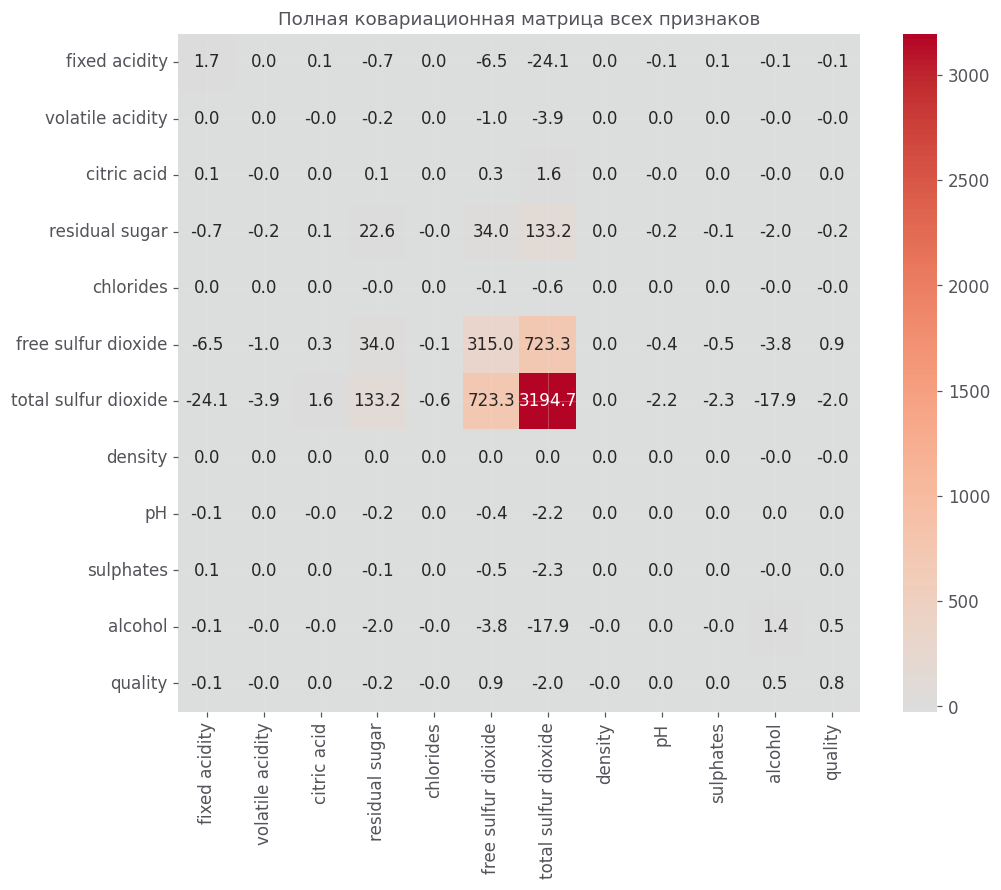


Ковариационная матрица 2x2 для выбранных признаков:


,free sulfur dioxide,total sulfur dioxide
free sulfur dioxide,315.04,723.26
total sulfur dioxide,723.26,3194.72


In [40]:
numeric_df = df.select_dtypes(include='number')
variances = numeric_df.var().sort_values(ascending=False)

print("Дисперсии всех числовых признаков (топ-5):")
display(variances.head(5).to_frame().style.format("{:.2f}"))

cov_full = numeric_df.cov()
plt.figure(figsize=(10, 8))
sns.heatmap(cov_full, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Полная ковариационная матрица всех признаков")
plt.show()

X = df['free sulfur dioxide']
Y = df['total sulfur dioxide']

cov_matrix_2x2 = np.cov(X, Y, ddof=1)

print("\nКовариационная матрица 2x2 для выбранных признаков:")
display(pd.DataFrame(
    np.round(cov_matrix_2x2, 2),
    index=["free sulfur dioxide", "total sulfur dioxide"],
    columns=["free sulfur dioxide", "total sulfur dioxide"]
))

### Дополнение: ковариации SO₂

Свободный и общий SO₂ измеряются в одинаковых единицах, мг/дм³.
Их выбираем для разбора ковариаций. Сравнение дисперсий всех признаков зависит от единиц
и само по себе не даёт основания считать эти два признака самыми информативными.

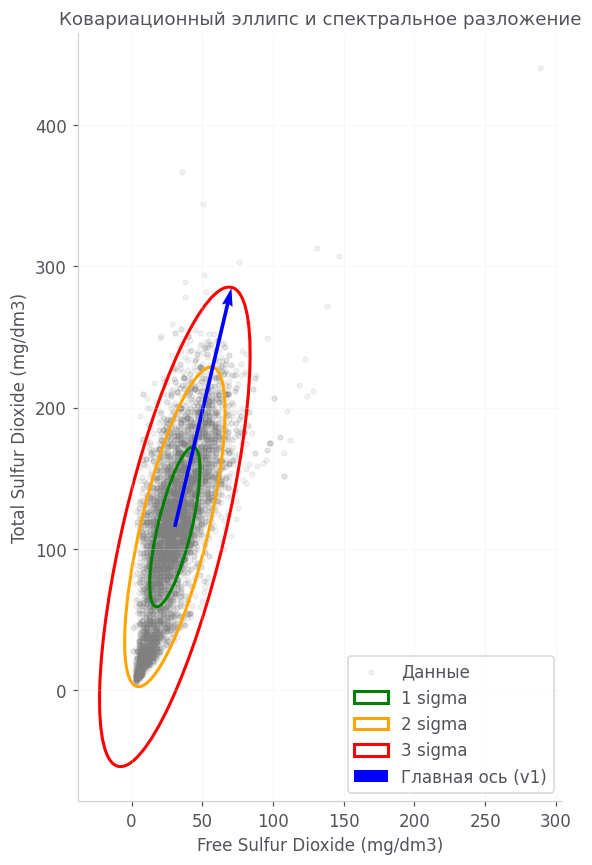

Собственные значения: lambda_1 = 3366.17, lambda_2 = 143.59
Доля дисперсии первой компоненты: 95.9%
Угол главной оси: 76.7°
Главный собственный вектор: [0.23065565 0.97303544]


In [41]:
def plot_confidence_ellipse(ax, cov, center, n_std, **kwargs):
    evals, evecs = np.linalg.eigh(cov)
    evals = evals[::-1]
    evecs = evecs[:, ::-1]

    scale = n_std

    width = 2 * np.sqrt(evals[0]) * scale
    height = 2 * np.sqrt(evals[1]) * scale
    angle = np.degrees(np.arctan2(evecs[1, 0], evecs[0, 0]))

    ellipse = patches.Ellipse(center, width, height, angle=angle, fill=False, **kwargs)
    ax.add_patch(ellipse)
    return angle, evecs[:, 0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(X, Y, alpha=0.1, s=10, color='gray', label='Данные')

angle_deg, main_axis_vec = plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=1, edgecolor='green', linewidth=2, label='1 sigma')
plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=2, edgecolor='orange', linewidth=2, label='2 sigma')
plot_confidence_ellipse(ax, cov_matrix_2x2, (X.mean(), Y.mean()), n_std=3, edgecolor='red', linewidth=2, label='3 sigma')

data_range = max(X.max() - X.min(), Y.max() - Y.min())
scale_vec = data_range * 0.4
ax.quiver(X.mean(), Y.mean(), main_axis_vec[0]*scale_vec, main_axis_vec[1]*scale_vec,
          color='blue', angles='xy', scale_units='xy', scale=1, label='Главная ось (v1)')

ax.set_xlabel("Free Sulfur Dioxide (mg/dm3)")
ax.set_ylabel("Total Sulfur Dioxide (mg/dm3)")
ax.set_title("Ковариационный эллипс и спектральное разложение")
ax.legend()
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

evals_final, _ = np.linalg.eigh(cov_matrix_2x2)
evals_final = evals_final[::-1]
print(f"Собственные значения: lambda_1 = {evals_final[0]:.2f}, lambda_2 = {evals_final[1]:.2f}")
print(f"Доля дисперсии первой компоненты: {evals_final[0] / np.sum(evals_final) * 100:.1f}%")
print(f"Угол главной оси: {angle_deg:.1f}°")
print(f"Главный собственный вектор: {main_axis_vec}")

Спектральное разложение ковариационной матрицы дало собственные значения $\lambda_1 = 3366.17$ и $\lambda_2 = 143.59$. Первая главная компонента объясняет 95.9% общей дисперсии, что указывает на сильную вытянутость облака точек вдоль одной оси. Угол наклона главной оси составляет 76.7°, что согласуется с доминированием дисперсии по оси total sulfur dioxide.

*Примечание:* Вероятностная интерпретация эллипсов (1$\sigma$ $\approx$ 39.3% и т.д.) строго верна только для двумерного нормального распределения. Поскольку маргинальные распределения этих признаков не являются строго нормальными, эллипсы используются здесь преимущественно как визуальный инструмент для демонстрации ковариационной структуры и главных направлений изменчивости.

In [42]:
print("Проверка нормальности (D'Agostino-Pearson):")
for col in ['free sulfur dioxide', 'total sulfur dioxide']:
    s = df[col]
    stat, p = stats.normaltest(s)
    print(f"  {col}: skew={stats.skew(s):.2f}, p={p:.3g}")

for color in ['red', 'white']:
    sub = df[df['color'] == color]
    r_sub, p_sub = stats.pearsonr(sub['free sulfur dioxide'], sub['total sulfur dioxide'])
    print(f"Пирсон для {color}: r={r_sub:.4f}, p={p_sub:.3g}")

r, p = stats.pearsonr(df['free sulfur dioxide'], df['total sulfur dioxide'])
print(f"\nОбщий Пирсон: r={r:.4f}, p={p:.3g}")
print("Примечание: p-value = 0 в float64 - численное округление очень малого p-value.")


r = float(r)
p_value = float(p)
n_samples = len(df)

t_stat_manual = (r * np.sqrt(n_samples - 2)) / np.sqrt(1 - r**2)

print(f"Коэффициент корреляции Пирсона (r): {r:.4f}")
print(f"t-статистика: {t_stat_manual:.4f}")
print(f"Степени свободы: {n_samples - 2}")
print(f"p-value: {p_value:.6g}")

if p_value < 0.05:
    print("\nВывод: p-value < 0.05. Нулевая гипотеза H0 отвергается.")
    print("Существует статистически значимая линейная зависимость между свободным и общим диоксидом серы.")
else:
    print("\nВывод: p-value >= 0.05. Нет оснований отвергать H0.")

Проверка нормальности (D'Agostino-Pearson):
  free sulfur dioxide: skew=1.22, p=0
  total sulfur dioxide: skew=-0.00, p=4.21e-13
Пирсон для red: r=0.6677, p=6.4e-207
Пирсон для white: r=0.6155, p=0

Общий Пирсон: r=0.7209, p=0
Примечание: p-value = 0 в float64 - численное округление очень малого p-value.
Коэффициент корреляции Пирсона (r): 0.7209
t-статистика: 83.8397
Степени свободы: 6495
p-value: 0

Вывод: p-value < 0.05. Нулевая гипотеза H0 отвергается.
Существует статистически значимая линейная зависимость между свободным и общим диоксидом серы.


Свободный и общий SO₂ связаны по данным: положительная корреляция есть и внутри типов вина.
Физически total = free + bound, но одна эта формула без предположений о bound не доказывает зависимость.
Тест Пирсона здесь приближённый: нормальность нарушена, строки могут быть связаны неизвестными партиями.

### Выводы раздела

Кислотность имеет правостороннюю асимметрию. Нормальная модель отвергается;
из двух положительных семейств меньший AIC у логнормального.
Медиана красных вин вдвое выше медианы белых. Причину различия эти данные не устанавливают.

Повторный отбор показывает снижение ошибки среднего. Конечная поправка заметна на больших выборках.
Дополнительный анализ SO₂ показывает положительную связь внутри обоих типов вина.
Ковариационные эллипсы описывают геометрию, но не гарантируют вероятностное покрытие.

Источник: [Cortez et al. (2009)](https://doi.org/10.1016/j.dss.2009.05.016).

<a id="resume1"></a>

## Lab resume

### Сводные статистики и гипотезы

Дисперсия в сводке рассчитана с делителем N-1. Единицы среднего указаны рядом с величиной,
единицы дисперсии возводятся в квадрат. Для quality это условная числовая трактовка баллов.
Главная гипотеза первого спринта: равенство средних quality у красных и белых вин, тест Уэлча,
$\alpha=0{,}05$. Остальные проверки считаем разведочными; они не являются независимыми подтверждениями.

In [43]:
from wine_stats.data import load_wines
from scipy import stats
import pandas as pd
summary_data = load_wines(ROOT / 'data/raw')
summary_rows = []
for variable, unit in [('quality', 'баллы'), ('alcohol', '% об.'), ('volatile_acidity', 'г/дм³')]:
    for kind, frame in [('all', summary_data), *summary_data.groupby('wine_type')]:
        x = frame[variable]
        summary_rows.append({'variable': variable, 'unit': unit, 'wine_type': kind,
            'n': len(x), 'mean': x.mean(), 'median': x.median(), 'variance': x.var(ddof=1),
            'std': x.std(ddof=1), 'min': x.min(), 'q25': x.quantile(.25),
            'q75': x.quantile(.75), 'max': x.max(), 'skew': x.skew(), 'excess': x.kurt()})
summary = pd.DataFrame(summary_rows)
display(summary.round(4))
summary.to_csv(ROOT / 'reports/tables/sprint1_summary.csv', index=False)
red_q = summary_data.loc[summary_data.wine_type.eq('red'), 'quality']
white_q = summary_data.loc[summary_data.wine_type.eq('white'), 'quality']
welch = stats.ttest_ind(red_q, white_q, equal_var=False)
ci = welch.confidence_interval()
hypotheses = pd.DataFrame([{'hypothesis': 'mean quality red = white', 'test': 'Welch',
    'difference_red_minus_white': red_q.mean()-white_q.mean(),
    'ci95_low': ci.low, 'ci95_high': ci.high, 'p_value': welch.pvalue,
    'alpha': .05, 'reject': bool(welch.pvalue < .05)}])
display(hypotheses)
hypotheses.to_csv(ROOT / 'reports/tables/sprint1_hypotheses.csv', index=False)

,variable,unit,wine_type,n,mean,median,variance,std,min,q25,q75,max,skew,excess
0,quality,баллы,all,6497,5.8184,6.00,0.7626,0.8733,3.00,5.00,6.00,9.00,0.1896,0.2323
1,quality,баллы,red,1599,5.6360,6.00,0.6522,0.8076,3.00,5.00,6.00,8.00,0.2178,0.2967
2,quality,баллы,white,4898,5.8779,6.00,0.7844,0.8856,3.00,5.00,6.00,9.00,0.1558,0.2165
3,alcohol,% об.,all,6497,10.4918,10.30,1.4226,1.1927,8.00,9.50,11.30,14.90,0.5657,-0.5317
4,alcohol,% об.,red,1599,10.4230,10.20,1.1356,1.0657,8.40,9.50,11.10,14.90,0.8608,0.2000
5,alcohol,% об.,white,4898,10.5143,10.40,1.5144,1.2306,8.00,9.50,11.40,14.20,0.4873,-0.6984
6,volatile_acidity,г/дм³,all,6497,0.3397,0.29,0.0271,0.1646,0.08,0.23,0.40,1.58,1.4951,2.8254
7,volatile_acidity,г/дм³,red,1599,0.5278,0.52,0.0321,0.1791,0.12,0.39,0.64,1.58,0.6716,1.2255
8,volatile_acidity,г/дм³,white,4898,0.2782,0.26,0.0102,0.1008,0.08,0.21,0.32,1.10,1.5770,5.0916


,hypothesis,test,difference_red_minus_white,ci95_low,ci95_high,p_value,alpha,reject
0,mean quality red = white,Welch,-0.241887,-0.288617,-0.195156,8.168349e-24,0.05,True


Средняя оценка белых вин выше красных; доверительный интервал разности не включает ноль.
Крепость положительно связана с качеством внутри обоих типов вина. Летучая кислотность выше у красных.
Нормальность не является подходящим общим предположением для этих трёх величин.
Стандартизация меняет масштаб, а не форму распределения.

Повторные выборки показывают уменьшение ошибки среднего с ростом n.
Без возвращения нужна поправка на конечную совокупность. Ни значимость теста, ни близость одного
выборочного среднего к генеральному не гарантируют перенос результата на новые вина.

### cat_mark_table

Официальные cat_id и coeff не заданы. В таблице перечислены выполненные части, без оценки баллов.

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| | [Три величины](#rv01) | | Природа случайности, EDA, распределения, стандартизация |
| | [Выборки](#rv02) | | Отбор с возвращением и без, повторные оценки среднего |
| | [Гипотеза](#resume1) | | Уэлч, разность средних и 95% интервал |
| | [Связь величин](#rv02) | | Корреляции внутри типов вина; ограничения причинной интерпретации |
| | [Дополнения](#rv03) | | Нормы, kNN и ковариации SO₂ внутри исходных разделов |

<a id="sprint2"></a>

# Lab01 - sprint 2

Сначала воспроизводим разбиение и выбор модели, затем генерацию.
Не смешиваем классификатор по 12 признакам из первого спринта с регрессией по одному alcohol.
Полные совпадающие строки не пересекают границы train, validation и test.

<a id="split"></a>

## Подготовка данных

Источник раздела: [00_data_split.ipynb](sprint2/00_data_split.ipynb).

### Подготовка: предсказание quality по alcohol

[Описание](#split-description) · [Данные](#split-data) · [Разделение](#split-split) · [Проверки](#split-tests) · [Выводы](#split-resume)

<a id="split-description"></a>
### Description
Вход модели - только `alcohol` (% об.). Цель - `quality`, порядковая оценка дегустаторов.
Регрессия будет приближать среднюю числовую оценку при данном содержании спирта;
это допущение о шкале, а не доказательство причинного влияния алкоголя.
`wine_type` используется для контроля состава частей, но не входит в X.

Этот этап готовит независимый от обучения holdout. Затем сравним константный прогноз,
линейную регрессию и kNN. Подбор моделей и преобразований - только внутри train.
Генератор условного распределения качества - отдельный следующий этап:
одна регрессия не выполняет требование лабораторной о ГСЧ.

In [44]:
from pathlib import Path
import sys
import hashlib
import json
import platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines, model_parts

SEED = 42
TEST_FRACTION = 0.2
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__})

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


<a id="split-data"></a>
### Данные и аудит
Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).
Исходный [ZIP](https://archive.ics.uci.edu/static/public/186/wine+quality.zip).
CSV не изменяются; повторы сохраняются. Причина их появления неизвестна.
Контрольные суммы фиксируют точные входные файлы.

In [45]:
raw = ROOT / 'data/raw'
df = load_wines(raw)
source_info = {
    f'winequality-{kind}.csv': {
        'sha256': hashlib.sha256((raw / f'winequality-{kind}.csv').read_bytes()).hexdigest(),
        'rows': int(df.wine_type.eq(kind).sum())
    } for kind in ('red', 'white')
}
audit = pd.DataFrame([{
    'rows': len(df), 'columns': len(df.columns),
    'missing_cells': int(df.isna().sum().sum()),
    'full_duplicate_rows': int(df.duplicated().sum()),
    'unique_rows': len(df.drop_duplicates())
}])
display(audit)
display(df.dtypes.rename('dtype').to_frame())
print(json.dumps(source_info, indent=2))

,rows,columns,missing_cells,full_duplicate_rows,unique_rows
0,6497,13,0,1177,5320


,dtype
fixed_acidity,float64
volatile_acidity,float64
citric_acid,float64
residual_sugar,float64
chlorides,float64
free_sulfur_dioxide,float64
total_sulfur_dioxide,float64
density,float64
pH,float64
sulphates,float64


{
  "winequality-red.csv": {
    "sha256": "4a402cf041b025d4566d954c3b9ba8635a3a8a01e039005d97d6a710278cf05e",
    "rows": 1599
  },
  "winequality-white.csv": {
    "sha256": "76c3f809815c17c07212622f776311faeb31e87610d52c26d87d6e361b169836",
    "rows": 4898
  }
}


<a id="split-split"></a>
### Разделение без пересечения полных повторов
Одинаковые строки по всем 11 измерениям, качеству и типу вина образуют одну группу.
Совпадение только пары `alcohol, quality` не означает дубликат.
В каждом типе вина случайно выбираем около 20% **групп** для test, остальные - train.
Поэтому доля строк может немного отличаться от 20%.
Полные повторы остаются в одной части. Связь между партиями проверить нельзя: их номера неизвестны.
Seed фиксирован заранее; распределение quality не используется для выбора удачного разбиения.

In [46]:
manifest = split_wines(df, test_fraction=TEST_FRACTION, seed=SEED)
parts = model_parts(df, manifest)
X_train, y_train = parts['train']
X_test, y_test = parts['test']
summary = (manifest.groupby(['split', 'wine_type'])
           .agg(rows=('row_id', 'size'), groups=('group_id', 'nunique'))
           .reset_index())
summary['share_within_type'] = summary['rows'] / summary.wine_type.map(df.wine_type.value_counts())
display(summary)
print({'X_train': X_train.shape, 'X_test': X_test.shape})
# Здесь нет масштабирования и обучения; test сохраняется для финальной оценки.

,split,wine_type,rows,groups,share_within_type
0,test,red,314,272,0.196373
1,test,white,988,792,0.201715
2,train,red,1285,1087,0.803627
3,train,white,3910,3169,0.798285


{'X_train': (5195, 1), 'X_test': (1302, 1)}


<a id="split-tests"></a>
### Tests и сохранение разбиения

In [47]:
assert len(manifest) == len(df) and manifest.row_id.is_unique
assert manifest.groupby('group_id').split.nunique().max() == 1
assert set(manifest.split) == {'train', 'test'}
assert len(X_train) + len(X_test) == len(df)
assert list(X_train.columns) == list(X_test.columns) == ['alcohol']
assert set(X_train.index).isdisjoint(X_test.index)
pd.testing.assert_frame_equal(manifest, split_wines(df, seed=SEED, test_fraction=TEST_FRACTION))

out = ROOT / 'data/processed'
out.mkdir(parents=True, exist_ok=True)
manifest.to_csv(out / 'alcohol_quality_split.csv', index=False)
metadata = {
    'seed': SEED, 'test_group_fraction': TEST_FRACTION,
    'features': ['alcohol'], 'target': 'quality',
    'source': 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip',
    'files': source_info,
    'manifest_sha256': hashlib.sha256((out / 'alcohol_quality_split.csv').read_bytes()).hexdigest(),
    'numpy': np.__version__, 'pandas': pd.__version__,
    'created_utc': datetime.now(timezone.utc).isoformat(),
}
(out / 'alcohol_quality_split.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
summary.to_csv(out / 'alcohol_quality_split_summary.csv', index=False)
print('Проверки пройдены; manifest, metadata и summary сохранены в data/processed.')

Проверки пройдены; manifest, metadata и summary сохранены в data/processed.


<a id="split-resume"></a>
### Выводы раздела
Исходные данные: 6497 наблюдений, 1177 полных повторов сверх первых вхождений,
пропусков нет. Повторы сохранены; группы не пересекают границу train/test.
При seed=42 получено 5195 обучающих и 1302 тестовых наблюдения
(20.04% строк в test). В test 314 красных и 988 белых вин.
Доля test внутри типов: 19.64% и 20.17% соответственно.

Подготовлены X с одним признаком `alcohol` и y=`quality`.
Модель ещё не обучена; вывод о предсказательной силе спирта пока не сделан.
Следующий этап - baseline и линейная регрессия с оценкой MAE, RMSE и R²;
для выбора модели потребуется валидация внутри train.

<a id="models"></a>

## Baseline и линейная регрессия

Источник раздела: [01_alcohol_quality_models.ipynb](sprint2/01_alcohol_quality_models.ipynb).

### Предсказание качества по содержанию спирта
### Модели и метрики

Сравним два прогноза: среднее качество обучающей выборки и линейную зависимость от спирта.
Качество измеряется в баллах. Для регрессии считаем разницу между соседними баллами одинаковой.

Линейная модель:

$$
\hat q = a + bx
$$

Коэффициенты находим методом наименьших квадратов:

$$
b = \frac{\sum_i (x_i-\bar x)(q_i-\bar q)}{\sum_i (x_i-\bar x)^2}
$$

$$
a = \bar q - b\bar x
$$

Ошибки оцениваем по MAE, RMSE и R²:

$$
\mathrm{MAE} = \frac{1}{n}\sum_i |q_i-\hat q_i|
$$

$$
\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_i (q_i-\hat q_i)^2}
$$

$$
R^2 = 1 - \frac{\sum_i (q_i-\hat q_i)^2}{\sum_i (q_i-\bar q)^2}
$$

MAE и RMSE - в баллах, R² - безразмерный. Основная метрика - RMSE.
Прогнозы не округляем.

In [48]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.regression import fit_linear, regression_metrics
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__})
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
from wine_stats.plotting import use_style
use_style()

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


### Разделение данных

Сначала запускаем `00_data_split.ipynb`. Из train выделяем около 20% групп для validation, seed = 43.
Полные дубликаты остаются в одной части. Test сохраняем для итоговой проверки выбранной модели.

In [49]:
processed = ROOT / 'data/processed'
meta = json.loads((processed / 'alcohol_quality_split.json').read_text())
for name, info in meta['files'].items():
    assert hashlib.sha256((ROOT / 'data/raw' / name).read_bytes()).hexdigest() == info['sha256']
manifest_path = processed / 'alcohol_quality_split.csv'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == meta['manifest_sha256']
manifest = pd.read_csv(manifest_path)
df = load_wines(ROOT / 'data/raw')
pd.testing.assert_frame_equal(manifest, split_wines(df, seed=meta['seed'], test_fraction=meta['test_group_fraction']))
outer_train = manifest['split'].eq('train')
train_data = df.loc[outer_train].reset_index(drop=True)
inner = split_wines(train_data, seed=43, test_fraction=0.2)
roles = manifest.copy()
roles.loc[outer_train, 'split'] = inner['split'].replace({'train': 'fit', 'test': 'validation'}).to_numpy()
assert roles.groupby('group_id')['split'].nunique().max() == 1
assert set(roles['split']) == {'fit', 'validation', 'test'}
assert roles.loc[manifest['split'].eq('test'), 'split'].eq('test').all()
roles.to_csv(processed / 'alcohol_quality_validation_split.csv', index=False)
display(pd.crosstab(roles['split'], roles.wine_type))
fit = df.loc[roles['split'].eq('fit')]
validation = df.loc[roles['split'].eq('validation')]

wine_type,red,white
split,,
fit,1024,3134
test,314,988
validation,261,776


### Обучение и сравнение

Обе модели обучаем на одних данных. Единственный признак - содержание спирта.

In [50]:
baseline = float(fit.quality.mean())
a, b = fit_linear(fit.alcohol.to_numpy(), fit.quality.to_numpy())
rows = []
for part, frame in [('fit', fit), ('validation', validation)]:
    for model, prediction in [('mean', np.full(len(frame), baseline)),
                              ('linear', a + b * frame.alcohol.to_numpy())]:
        rows.append({'split': part, 'model': model, 'n': len(frame),
                     **regression_metrics(frame.quality.to_numpy(), prediction)})
metrics = pd.DataFrame(rows)
print(f'Baseline: {baseline:.4f}; linear: quality = {a:.4f} + {b:.4f} * alcohol')
display(metrics.round(4))
by_type = []
for kind, frame in validation.groupby('wine_type'):
    for model, prediction in [('mean', np.full(len(frame), baseline)),
                              ('linear', a + b * frame.alcohol.to_numpy())]:
        by_type.append({'wine_type': kind, 'model': model, 'n': len(frame),
                        **regression_metrics(frame.quality.to_numpy(), prediction)})
by_type = pd.DataFrame(by_type)
display(by_type.round(4))
tables = ROOT / 'reports/tables'
tables.mkdir(parents=True, exist_ok=True)
metrics.to_csv(tables / 'alcohol_quality_validation_metrics.csv', index=False)
by_type.to_csv(tables / 'alcohol_quality_validation_by_type.csv', index=False)
np.testing.assert_allclose([a,b], np.linalg.lstsq(np.column_stack([np.ones(len(fit)),fit.alcohol]),fit.quality,rcond=None)[0])

Baseline: 5.8158; linear: quality = 2.2940 + 0.3354 * alcohol


,split,model,n,MAE,RMSE,R2
0,fit,mean,4158,0.6918,0.8823,0.0000
1,fit,linear,4158,0.6165,0.7850,0.2085
2,validation,mean,1037,0.6779,0.8586,-0.0000
3,validation,linear,1037,0.6093,0.7676,0.2007


,wine_type,model,n,MAE,RMSE,R2
0,red,mean,261,0.6658,0.8168,-0.0556
1,red,linear,261,0.5719,0.6997,0.2254
2,white,mean,776,0.6820,0.8722,-0.0050
3,white,linear,776,0.6219,0.7892,0.1772


### Графики на validation

Слева - оценки и прогнозы, справа - остатки: наблюдаемое качество минус прогноз.

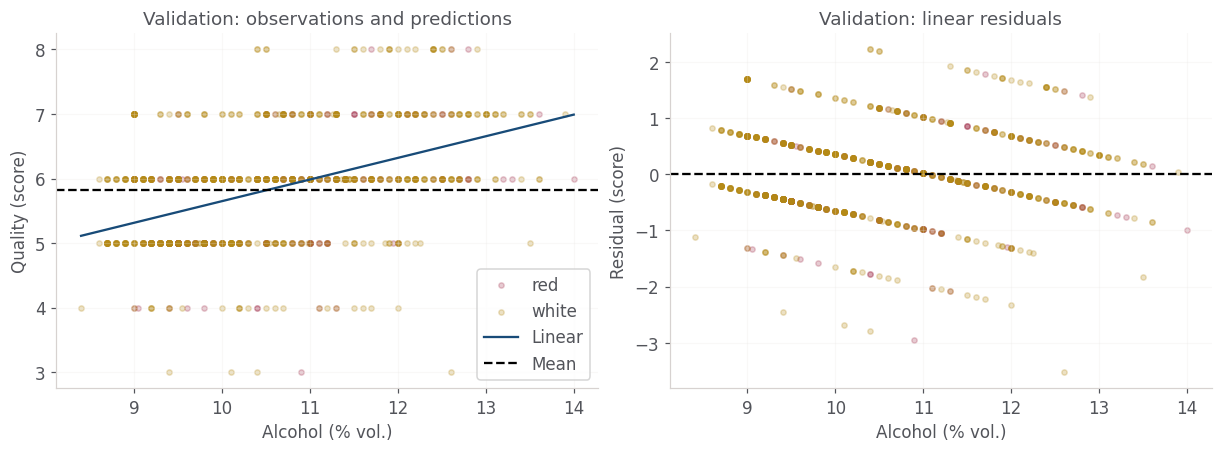

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = {'red': '#a3324d', 'white': '#b58a16'}
for kind, frame in validation.groupby('wine_type'):
    axes[0].scatter(frame.alcohol, frame.quality, s=12, alpha=0.25, color=colors[kind], label=kind)
    axes[1].scatter(frame.alcohol, frame.quality-(a+b*frame.alcohol), s=12, alpha=0.25, color=colors[kind])
x = np.linspace(validation.alcohol.min(), validation.alcohol.max(), 100)
axes[0].plot(x, a+b*x, color='#184b78', label='Linear')
axes[0].axhline(baseline, color='black', linestyle='--', label='Mean')
axes[0].set(xlabel='Alcohol (% vol.)', ylabel='Quality (score)', title='Validation: observations and predictions')
axes[0].legend()
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Alcohol (% vol.)', ylabel='Residual (score)', title='Validation: linear residuals')
figures = ROOT / 'reports/figures'
figures.mkdir(parents=True, exist_ok=True)
figure_path = figures / 'alcohol_quality_validation.png'
fig.savefig(figure_path)
plt.close(fig)
display(Image(filename=str(figure_path)))

### Выводы раздела

Результаты на validation:

In [52]:
val = metrics.loc[metrics['split'].eq('validation')].set_index('model')
gain = 100 * (1-val.loc['linear','RMSE']/val.loc['mean','RMSE'])
print(f"На validation n={len(validation)}: RMSE baseline={val.loc['mean','RMSE']:.4f}, "
      f"linear={val.loc['linear','RMSE']:.4f}; снижение RMSE={gain:.2f}%.")
print(f"MAE linear={val.loc['linear','MAE']:.4f} балла; R²={val.loc['linear','R2']:.4f}.")
print(f"Наклон {b:.4f} балла на +1 процентный пункт спирта - ассоциация в модели, не причинный эффект.")
print('Одного содержания спирта недостаточно для точного восстановления оценки отдельного вина.')
print('Связь не доказывает, что увеличение спирта само по себе повышает качество.')

На validation n=1037: RMSE baseline=0.8586, linear=0.7676; снижение RMSE=10.60%.
MAE linear=0.6093 балла; R²=0.2007.
Наклон 0.3354 балла на +1 процентный пункт спирта - ассоциация в модели, не причинный эффект.
Одного содержания спирта недостаточно для точного восстановления оценки отдельного вина.
Связь не доказывает, что увеличение спирта само по себе повышает качество.


<a id="knn"></a>

## Выбор числа соседей

Источник раздела: [02_knn.ipynb](sprint2/02_knn.ipynb).

### kNN: прогноз по похожим винам

Ищем вина с ближайшим содержанием спирта и усредняем их оценки.

$$
d(x,x_i)=|x-x_i|,\qquad \hat q(x)=\frac{1}{|N(x)|}\sum_{i\in N(x)}q_i
$$

Если на границе k соседей несколько вин имеют одинаковое расстояние, берём все.
Так результат не зависит от порядка строк. Поэтому соседей может быть больше k.

После первого сравнения расширяем сетку: k = 5, 15, 30, 60, 120, 240, 480, 720, 960, 1440, 2160, 3200, 4158.
Сравниваем по RMSE на прежней validation.
При равных RMSE выбираем большее k. Test не используем.
Сначала запускаем ноутбук подготовки данных.

In [53]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.regression import fit_linear, regression_metrics
print({'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__})
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.2})
from wine_stats.plotting import use_style
use_style()

{'python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3'}


In [54]:
processed = ROOT / 'data/processed'
meta = json.loads((processed / 'alcohol_quality_split.json').read_text())
for name, info in meta['files'].items():
    assert hashlib.sha256((ROOT / 'data/raw' / name).read_bytes()).hexdigest() == info['sha256']
manifest_path = processed / 'alcohol_quality_split.csv'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest() == meta['manifest_sha256']
manifest = pd.read_csv(manifest_path)
df = load_wines(ROOT / 'data/raw')
pd.testing.assert_frame_equal(manifest, split_wines(df, seed=meta['seed'], test_fraction=meta['test_group_fraction']))
outer_train = manifest['split'].eq('train')
train_data = df.loc[outer_train].reset_index(drop=True)
inner = split_wines(train_data, seed=43, test_fraction=0.2)
roles = manifest.copy()
roles.loc[outer_train, 'split'] = inner['split'].replace({'train': 'fit', 'test': 'validation'}).to_numpy()
assert roles.groupby('group_id')['split'].nunique().max() == 1
assert set(roles['split']) == {'fit', 'validation', 'test'}
assert roles.loc[manifest['split'].eq('test'), 'split'].eq('test').all()
roles.to_csv(processed / 'alcohol_quality_validation_split.csv', index=False)
display(pd.crosstab(roles['split'], roles.wine_type))
fit = df.loc[roles['split'].eq('fit')]
validation = df.loc[roles['split'].eq('validation')]

wine_type,red,white
split,,
fit,1024,3134
test,314,988
validation,261,776


In [55]:
from wine_stats.regression import predict_knn
candidates = [5,15,30,60,120,240,480,720,960,1440,2160,3200,len(fit)]
rows=[]
for k in candidates:
    prediction=predict_knn(fit.alcohol,fit.quality,validation.alcohol,k)
    rows.append({'k':k, **regression_metrics(validation.quality,prediction)})
search=pd.DataFrame(rows)
best_k=int(search.sort_values(['RMSE','k'],ascending=[True,False]).iloc[0]['k'])
display(search.round(4))
a,b=fit_linear(fit.alcohol,fit.quality)
predictions={
    'mean':np.full(len(validation),fit.quality.mean()),
    'linear':a+b*validation.alcohol.to_numpy(),
    'knn':predict_knn(fit.alcohol,fit.quality,validation.alcohol,best_k)}
comparison=pd.DataFrame([{'model':name,**regression_metrics(validation.quality,p)} for name,p in predictions.items()])
display(comparison.round(4))
tables=ROOT/'reports/tables'
search.to_csv(tables/'knn_validation_search.csv',index=False)
comparison.to_csv(tables/'knn_validation_comparison.csv',index=False)
print('Выбрано k =',best_k)

,k,MAE,RMSE,R2
0,5,0.6147,0.7690,0.1977
1,15,0.6146,0.7691,0.1977
2,30,0.6142,0.7686,0.1986
3,60,0.6151,0.7684,0.1990
4,120,0.6106,0.7671,0.2018
5,240,0.6073,0.7610,0.2143
6,480,0.6070,0.7590,0.2186
7,720,0.6071,0.7589,0.2187
8,960,0.6089,0.7618,0.2127
9,1440,0.6112,0.7662,0.2036


,model,MAE,RMSE,R2
0,mean,0.6779,0.8586,-0.0000
1,linear,0.6093,0.7676,0.2007
2,knn,0.6071,0.7589,0.2187


Выбрано k = 720


### Выводы раздела

После расширения сетки минимальная RMSE получена при k = 720: 0,75894 против 0,75899 при k = 480.
Разница около 0,00005 балла - практически ничтожная; уверенного преимущества одного k над другим не установлено.
По заранее выбранному правилу минимума RMSE выбираем k = 720. При k ≥ 960 ошибка начинает расти.
При k = 4158 модель использует всю обучающую часть и совпадает с прогнозом средним.

Линейная модель даёт RMSE = 0,76762. Выигрыш kNN - около 1,1%.
Лучший вариант теперь внутри проверенной сетки.

Значение k выбрано по этой же validation, поэтому её результат может быть оптимистичным.
Итоговую ошибку выбранной модели нужно оценить на отложенном test.

<a id="holdout"></a>

## Оценка модели на test

Источник раздела: [03_final_test.ipynb](sprint2/03_final_test.ipynb).

### Итоговая проверка модели

По validation выбрали kNN с k = 720. Теперь используем весь train, включая бывшую validation.
k не меняем. Полные повторы на границе 720 соседей включаем целиком.
У kNN обучение состоит в сохранении обучающих наблюдений; коэффициенты не подбираются.
Baseline и линейную модель пересчитываем на тех же данных.

Единственный признак - alcohol. Test используем для итоговой оценки, без дальнейшего подбора по его результатам.

In [56]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.regression import fit_linear, predict_knn, regression_metrics

K=720
processed=ROOT/'data/processed'
meta=json.loads((processed/'alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
manifest_path=processed/'alcohol_quality_split.csv'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest()==meta['manifest_sha256']
manifest=pd.read_csv(manifest_path)
df=load_wines(ROOT/'data/raw')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=meta['seed'],test_fraction=meta['test_group_fraction']))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]
test=df.loc[manifest['split'].eq('test')]
print(f'Train: {len(train)}; test: {len(test)}; k = {K}')

Train: 5195; test: 1302; k = 720


In [57]:
baseline=float(train.quality.mean())
a,b=fit_linear(train.alcohol,train.quality)
predictions={
    'mean':np.full(len(test),baseline),
    'linear':a+b*test.alcohol.to_numpy(),
    'knn':predict_knn(train.alcohol,train.quality,test.alcohol,K)}
metrics=pd.DataFrame([{'model':name,'n':len(test),**regression_metrics(test.quality,p)}
                      for name,p in predictions.items()])
display(metrics.round(4))
by_type=[]
for kind in ('red','white'):
    mask=test.wine_type.eq(kind).to_numpy()
    for name,p in predictions.items():
        by_type.append({'wine_type':kind,'model':name,'n':int(mask.sum()),
                        **regression_metrics(test.quality.to_numpy()[mask],p[mask])})
by_type=pd.DataFrame(by_type)
display(by_type.round(4))
tables=ROOT/'reports/tables'
metrics.to_csv(tables/'final_test_metrics.csv',index=False)
by_type.to_csv(tables/'final_test_by_type.csv',index=False)
# Local model artifact: kNN requires the training observations for prediction.
np.savez(processed/'quality_knn_model.npz',alcohol=train.alcohol.to_numpy(),
         quality=train.quality.to_numpy(),k=np.array(K))
saved=np.load(processed/'quality_knn_model.npz',allow_pickle=False)
np.testing.assert_allclose(
    predict_knn(saved['alcohol'],saved['quality'],test.alcohol,int(saved['k'])),
    predictions['knn'])
test_predictions=pd.DataFrame({'row_id':manifest.loc[test.index,'row_id'],
                               'quality':test.quality,**predictions})
test_predictions.to_csv(processed/'final_test_predictions.csv',index=False)
print(f'Линейная модель: quality = {a:.4f} + {b:.4f} × alcohol')

,model,n,MAE,RMSE,R2
0,mean,1302,0.6751,0.8553,-0.0003
1,linear,1302,0.6306,0.7856,0.1560
2,knn,1302,0.6270,0.7770,0.1744


,wine_type,model,n,MAE,RMSE,R2
0,red,mean,314,0.6812,0.8062,-0.0856
1,red,linear,314,0.5926,0.7110,0.1556
2,red,knn,314,0.5801,0.7005,0.1805
3,white,mean,988,0.6732,0.8703,-0.0109
4,white,linear,988,0.6426,0.8079,0.1289
5,white,knn,988,0.6420,0.7998,0.1462


Линейная модель: quality = 2.3132 + 0.3335 × alcohol


### Выводы раздела

Численные результаты:

In [58]:
result=metrics.set_index('model')
gain=100*(1-result.loc['knn','RMSE']/result.loc['mean','RMSE'])
print(f"kNN: MAE = {result.loc['knn','MAE']:.4f}, RMSE = {result.loc['knn','RMSE']:.4f} балла; R² = {result.loc['knn','R2']:.4f}.")
print(f"Снижение RMSE относительно среднего: {gain:.2f}%.")
print(f"Разность RMSE (kNN − линейная): {result.loc['knn','RMSE']-result.loc['linear','RMSE']:.4f} балла.")

kNN: MAE = 0.6270, RMSE = 0.7770 балла; R² = 0.1744.
Снижение RMSE относительно среднего: 9.15%.
Разность RMSE (kNN − линейная): -0.0086 балла.


По содержанию спирта можно приблизительно предсказать оценку вина дегустатором.
На 1302 тестовых винах модель kNN ошибается в среднем на 0,63 балла, а прогноз одним общим средним - на 0,68 балла.
Учёт спирта улучшил результат, но ненамного: вина одинаковой крепости могут получать разные оценки.
Для более точного прогноза можно исследовать другие характеристики вина, но улучшение нужно проверить отдельно.

Модель прогнозирует числовую оценку дегустаторов. Связь между крепостью и оценкой не доказывает причинное влияние спирта.
Результат относится к этому датасету и не гарантирует такую же ошибку на винах других регионов.
Различия моделей не проверялись на статистическую значимость.

<a id="generator"></a>

## random 01: quality при заданной крепости

Источник раздела: [01_generator.ipynb](sprint2/01_generator.ipynb).

### Description

Прогноз kNN даёт среднюю оценку. Генератор выдаёт отдельные целые оценки с частотами,
наблюдаемыми у ближайших по крепости вин обучающей выборки. k = 720, совпадения на границе сохраняем.
Это модель условного распределения, а не воспроизведение дегустации конкретного вина.
k выбран для среднего прогноза; оптимальность для всего распределения не установлена.

### math desc - метод обратной функции распределения

Каждой оценке выделяем интервал от 0 до 1. Его длина равна доле этой оценки среди соседей.
Равномерное случайное число выбирает интервал, а вместе с ним - оценку.

**Пример.** Числа в таблице условные и поясняют алгоритм.

| Оценка | Вероятность | Интервал для U |
|---|---:|---|
| 5 | 0,20 | [0; 0,20) |
| 6 | 0,50 | [0,20; 0,70) |
| 7 | 0,30 | [0,70; 1) |

Если U = 0,54, генератор возвращает 6. Вероятность получить шестёрку равна длине её интервала:

$$
P(Q^*=6)=P(0{,}20\le U<0{,}70)=0{,}70-0{,}20=0{,}50.
$$

**Распределение по соседям.** При заданной крепости x выбираем m соседей из train.
Различные оценки обозначим q₁ < … < qᵣ; оценка qⱼ встречается nⱼ раз.
Тогда её оценённая вероятность:

$$
p_j(x)=\frac{n_j}{m},\qquad \sum_{j=1}^{r}p_j(x)=1.
$$

Берём k = 720, но m может быть больше: все совпадения расстояний на границе включаем целиком.

**Правило генерации.** Накапливаем вероятности:

$$
C_0=0,\qquad C_j=\sum_{i=1}^{j}p_i(x),\qquad C_r=1.
$$

Для равномерного U на [0; 1) возвращаем оценку qⱼ, если:

$$
C_{j-1}\le U<C_j.
$$

**Обоснование.** У равномерного распределения вероятность попасть в интервал равна его длине:

$$
P(Q^*=q_j\mid x)=P(C_{j-1}\le U<C_j)=C_j-C_{j-1}.
$$

Вычитая две накопленные суммы, получаем:

$$
C_j-C_{j-1}
=\left(\sum_{i=1}^{j-1}p_i(x)+p_j(x)\right)-\sum_{i=1}^{j-1}p_i(x)
=p_j(x).
$$

Следовательно:

$$
\boxed{P(Q^*=q_j\mid x)=p_j(x).}
$$

Генератор воспроизводит заданное распределение оценок. В коде ищем первую накопленную
вероятность, строго большую U: `searchsorted(cdf, U, side='right')`.
Это учитывает используемый интервал [0; 1) и пропускает оценки с нулевой вероятностью.
Базовые псевдослучайные равномерные числа получаем из NumPy.

**Связь с прогнозом kNN.** Среднее генератора равно среднему оценок соседей:

$$
\mu(x)=E[Q^*\mid x]=\sum_{j=1}^{r}q_jp_j(x)
=\frac{1}{m}\sum_{i\in N(x)}q_i.
$$

Дисперсия показывает разброс сгенерированных оценок:

$$
\operatorname{Var}(Q^*\mid x)=\sum_{j=1}^{r}(q_j-\mu(x))^2p_j(x).
$$

Эти формулы задают значения для проверки генератора. В конечной случайной выборке
среднее, дисперсия и частоты могут немного отличаться от них.
Доказательство относится к распределению соседей; соответствие новым реальным винам проверяется отдельно.

**Источник:** L. Devroye, *Non-Uniform Random Variate Generation* (1986), глава II, §2, с. 27-31.
[Текст книги](https://luc.devroye.org/LucDevroye-NonUniformRandomVariateGeneration-10.1007_978-1-4613-8643-8-1986.pdf).

### code

In [59]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, generate_quality
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
train=df.loc[manifest['split'].eq('train')]
ALCOHOL=12.
scores,p=quality_distribution(train.alcohol,train.quality,ALCOHOL,k=720)
print(generate_quality(train.alcohol,train.quality,ALCOHOL,20,k=720,seed=42))
display(pd.DataFrame({'quality':scores,'probability':p}))

[7 6 7 7 6 8 7 7 6 6 6 8 7 7 6 6 6 5 7 7]


,quality,probability
0,3,0.002519
1,4,0.013854
2,5,0.075567
3,6,0.505038
4,7,0.322418
5,8,0.078086
6,9,0.002519


### tests

Сравниваем генерацию с заданным распределением соседей. Это проверка реализации,
а не независимая проверка модели на новых винах.

In [60]:
sample=generate_quality(train.alcohol,train.quality,ALCOHOL,100000,k=720,seed=42)
mu=scores@p
comparison=pd.DataFrame({
    'metric':['mean','variance'],
    'neighbors_distribution':[mu,((scores-mu)**2)@p],
    'generated':[sample.mean(),sample.var()]})
display(comparison)
comparison.to_csv(ROOT/'reports/tables/generator_smoke_metrics.csv',index=False)

,metric,neighbors_distribution,generated
0,mean,6.375315,6.377880
1,variance,0.670222,0.672827


### resume

При 12% спирта среднее распределения соседей - 6,375 балла, генерации - 6,378.
Дисперсии - 0,670 и 0,673 балла². Небольшое расхождение связано со случайной генерацией.
Алгоритм прошёл тесты границ интервалов, частот, воспроизводимости и допустимых значений.
Сравнение с реальными данными приведено в `04_generator_comparison.ipynb`.

### Выводы раздела

<a id="comparison"></a>

## Генератор и реальные данные

Источник раздела: [04_generator_comparison.ipynb](sprint2/04_generator_comparison.ipynb).

### Генератор и реальные оценки
### Description

Для каждой крепости из test строим распределение оценок по соседям из train, k = 720.
Реальные оценки test при построении распределений не используем.
Генерируем по одной оценке на каждое тестовое вино и повторяем опыт 1000 раз, seed = 2026.
Так сравниваем одинаковый состав по крепости и одинаковые размеры выборок.

Test уже использовался для оценки регрессии. Это дополнительная диагностика фиксированного генератора,
а не новый независимый эксперимент. Параметры по результатам не меняем.

In [61]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]
test_all=df.loc[manifest['split'].eq('test')]
supported=test_all.alcohol.between(train.alcohol.min(),train.alcohol.max())
test=test_all.loc[supported]
print(f'Test: {len(test_all)}; в диапазоне train: {len(test)}; вне диапазона: {(~supported).sum()}')
K=720
REPEATS=1000
rng=np.random.default_rng(2026)
scores=np.arange(11)
probabilities=np.zeros((len(test),len(scores)))
for i,x in enumerate(test.alcohol):
    values,p=quality_distribution(train.alcohol,train.quality,x,k=K)
    probabilities[i,values]=p
assert np.allclose(probabilities.sum(axis=1),1)
generated=np.column_stack([inverse_cdf(scores,p,rng.random(REPEATS)) for p in probabilities])
observed=test.quality.to_numpy()

from wine_stats.plotting import use_style
use_style()

Test: 1302; в диапазоне train: 1302; вне диапазона: 0


### tests - метрики и частоты

«Модель» - точные метрики смеси распределений для тестовых крепостей.
«Генерация» - среднее метрики по 1000 опытам.
Диапазон 2,5-97,5% показывает разброс симуляций при фиксированной модели, а не доверительный интервал истинной характеристики вин.
Дисперсии считаем со знаменателем n; квантили - по обратной эмпирической функции распределения.

In [62]:
def statistics(a):
    return np.column_stack([a.mean(axis=1),a.var(axis=1),
        *np.quantile(a,[.25,.5,.75],axis=1,method='inverted_cdf')])
sim=statistics(generated)
real=statistics(observed[None,:])[0]
mixture=probabilities.mean(axis=0)
mu=scores@mixture
model=np.r_[mu,((scores-mu)**2)@mixture,
            scores[np.searchsorted(np.cumsum(mixture),[.25,.5,.75])]]
comparison=pd.DataFrame({'metric':['mean','variance','q25','median','q75'],
    'real':real,'model':model,'generated_mean':sim.mean(axis=0),
    'simulation_q025':np.quantile(sim,.025,axis=0),
    'simulation_q975':np.quantile(sim,.975,axis=0)})
display(comparison.round(4))
freq=np.array([(generated==q).mean(axis=1) for q in scores]).T
real_freq=np.array([(observed==q).mean() for q in scores])
frequencies=pd.DataFrame({'quality':scores,'real':real_freq,'model':mixture,
    'generated_mean':freq.mean(axis=0),'simulation_q025':np.quantile(freq,.025,axis=0),
    'simulation_q975':np.quantile(freq,.975,axis=0)})
display(frequencies.round(4))
tv=.5*np.abs(real_freq-mixture).sum()
print(f'Расстояние полной вариации реальность/модель: {tv:.4f}')
tables=ROOT/'reports/tables'
comparison.to_csv(tables/'generator_real_metrics.csv',index=False)
frequencies.to_csv(tables/'generator_real_frequencies.csv',index=False)

,metric,real,model,generated_mean,simulation_q025,simulation_q975
0,mean,5.8295,5.7816,5.7810,5.7381,5.8233
1,variance,0.7313,0.7383,0.7383,0.6836,0.7949
2,q25,5.0000,5.0000,5.0000,5.0000,5.0000
3,median,6.0000,6.0000,6.0000,6.0000,6.0000
4,q75,6.0000,6.0000,6.0000,6.0000,6.0000


,quality,real,model,generated_mean,simulation_q025,simulation_q975
0,0,0.0000,0.0000,0.0000,0.0000,0.0000
1,1,0.0000,0.0000,0.0000,0.0000,0.0000
2,2,0.0000,0.0000,0.0000,0.0000,0.0000
3,3,0.0031,0.0046,0.0046,0.0015,0.0084
4,4,0.0338,0.0331,0.0332,0.0246,0.0438
5,5,0.3195,0.3462,0.3464,0.3226,0.3710
6,6,0.4439,0.4363,0.4361,0.4109,0.4639
7,7,0.1736,0.1525,0.1523,0.1344,0.1713
8,8,0.0261,0.0264,0.0264,0.0177,0.0353
9,9,0.0000,0.0008,0.0008,0.0000,0.0031


Расстояние полной вариации реальность/модель: 0.0294


### Диагностика по крепости

Общее совпадение может скрывать ошибки в отдельных группах. Сравним средние в диапазонах
до 10%, 10-11%, 11-12% и от 12% спирта. Верхняя граница каждого интервала не включается.

,alcohol_bin,n,real_mean,model_mean,simulation_q025,simulation_q975
0,"[-inf, 10.0)",546,5.5110,5.4172,5.3571,5.4707
1,"[10.0, 11.0)",337,5.7804,5.7531,5.6647,5.8338
2,"[11.0, 12.0)",232,6.1164,6.1054,5.9956,6.2155
3,"[12.0, inf)",187,6.4920,6.4949,6.3797,6.6043


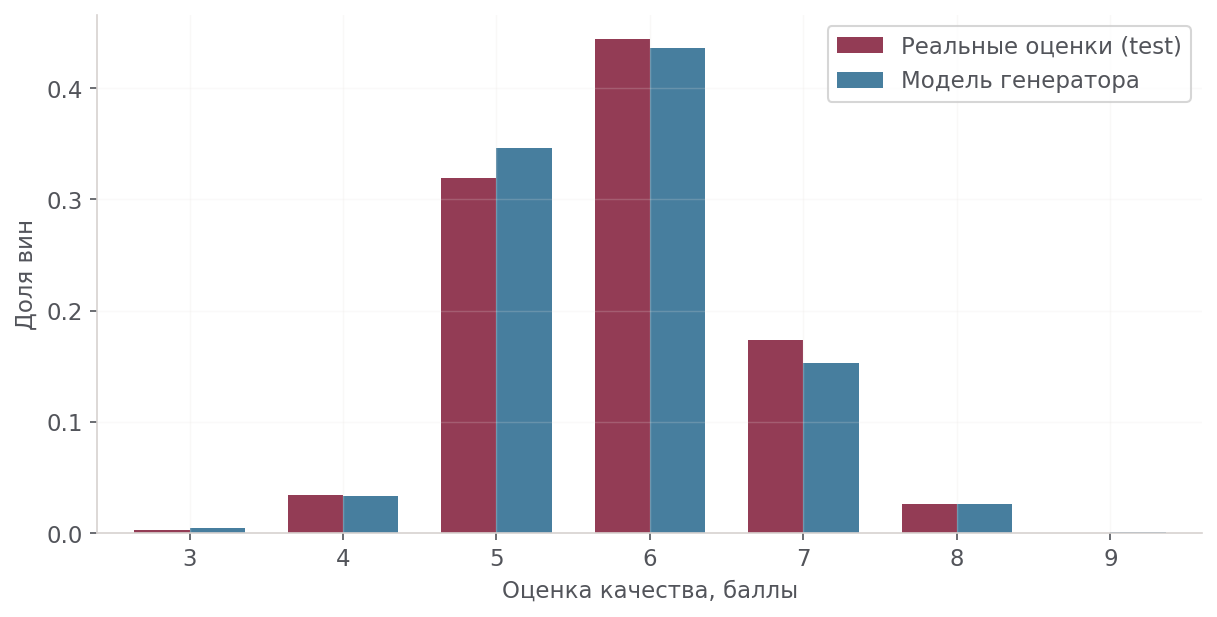

In [63]:
bins=pd.cut(test.alcohol,[-np.inf,10,11,12,np.inf],right=False)
groups=[]
for label in bins.cat.categories:
    mask=(bins==label).to_numpy()
    if not mask.any():continue
    group_p=probabilities[mask].mean(axis=0)
    means=generated[:,mask].mean(axis=1)
    groups.append({'alcohol_bin':str(label),'n':int(mask.sum()),
        'real_mean':observed[mask].mean(),'model_mean':group_p@scores,
        'simulation_q025':np.quantile(means,.025),'simulation_q975':np.quantile(means,.975)})
groups=pd.DataFrame(groups)
display(groups.round(4))
groups.to_csv(tables/'generator_real_by_alcohol.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
ax.bar(scores-.18,real_freq,width=.36,label='Реальные оценки (test)',color='#933c55')
ax.bar(scores+.18,mixture,width=.36,label='Модель генератора',color='#477e9e')
ax.set(xlabel='Оценка качества, баллы',ylabel='Доля вин',xticks=scores,xlim=(2.4,9.6))
ax.legend();ax.grid(axis='y',alpha=.2)
path=ROOT/'reports/figures/generator_real_frequencies.png'
fig.savefig(path,dpi=150);plt.close(fig)
display(Image(filename=str(path)))

### resume

Проверены все 1302 тестовых вина. Средняя реальная оценка - 5,829 балла,
средняя по 1000 генерациям - 5,781: генератор занижает её примерно на 0,048 балла.
Дисперсии близки: 0,731 у реальных данных и 0,738 в генерациях.
Квартили совпали: 5, 6 и 6 баллов.

Расстояние полной вариации между реальными частотами и моделью - 0,0294.
Это небольшое общее расхождение частот, но оно не доказывает совпадение условных распределений.
Главная заметная ошибка - у вин крепостью ниже 10%:
реальное среднее 5,511, модельное 5,417 (разница −0,094 балла).

Реальное общее среднее немного выше диапазона 2,5-97,5% симуляций.
Поэтому утверждать полное согласие с данными нельзя.
Генератор воспроизводит общий разброс, но имеет смещение для части вин.

Диапазоны симуляций отражают только случайность генерации при фиксированных вероятностях.
Они не учитывают неопределённость обучения и зависимость повторяющихся наблюдений.
Формальный тест равенства распределений здесь не проводился.
Для дисперсии сравнивается дисперсия смеси с эмпирической дисперсией конечной выборки;
их математические ожидания могут немного различаться.

### Выводы раздела

<a id="convergence"></a>

## Состоятельность оценок генератора

Источник раздела: [05_generator_convergence.ipynb](sprint2/05_generator_convergence.ipynb).

### Сходимость оценок генератора
### Description

Фиксируем крепость 12% об. и k = 720. Распределение строим только по train.
Для каждого объёма от 10 до 100 000 получаем 500 выборок. В каждом повторе используем вложенные выборки: увеличиваем одну последовательность.
Сравниваем среднее и исправленную дисперсию с точными характеристиками фиксированной модели. Test здесь не нужен.

In [64]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]

values,p=quality_distribution(train.alcohol,train.quality,12.,k=720)
mu=values@p
variance=((values-mu)**2)@p
moment4=((values-mu)**4)@p
print(f'Среднее модели: {mu:.6f}; дисперсия: {variance:.6f}')

from wine_stats.plotting import use_style
use_style()

Среднее модели: 6.375315; дисперсия: 0.670222


### math desc

При фиксированной модели сгенерированные оценки рассматриваем как независимые и одинаково распределённые. Они ограничены, поэтому все моменты конечны. По закону больших чисел среднее и средний квадрат сходятся к своим ожиданиям. Отсюда сходится и исправленная дисперсия:

$$
\bar Q_n\xrightarrow{P}\mu,\qquad S_n^2=\frac{n}{n-1}\left(\overline{Q^2}_n-\bar Q_n^2\right)\xrightarrow{P}\sigma^2.
$$

Обе оценки несмещённые. Их теоретические среднеквадратические ошибки равны:

$$
\operatorname{RMSE}(\bar Q_n)=\frac{\sigma}{\sqrt n},\qquad
\operatorname{RMSE}(S_n^2)=\sqrt{\frac{1}{n}\left(\mu_4-\frac{n-3}{n-1}\sigma^4\right)},
\quad \mu_4=E[(Q-\mu)^4].
$$

Проверим эти зависимости по повторным генерациям. Ошибка отдельной последовательности может временно расти: сходимость не означает монотонного приближения. Здесь проверяем точность генерации заданного распределения; увеличение n не исправляет расхождение модели с реальными винами.

In [65]:
sizes=np.array([10,30,100,300,1000,3000,10000,30000,100000])
repeats=500
rng=np.random.default_rng(2027)
means=np.empty((repeats,len(sizes)))
variances=np.empty_like(means)
for r in range(repeats):
    sample=inverse_cdf(values,p,rng.random(sizes[-1])).astype(float)
    sums=np.cumsum(sample)[sizes-1]
    squares=np.cumsum(sample**2)[sizes-1]
    means[r]=sums/sizes
    variances[r]=(squares-sums**2/sizes)/(sizes-1)
result=pd.DataFrame({'n':sizes,
    'mean_bias':(means-mu).mean(axis=0),
    'mean_rmse':np.sqrt(((means-mu)**2).mean(axis=0)),
    'mean_rmse_theory':np.sqrt(variance/sizes),
    'variance_bias':(variances-variance).mean(axis=0),
    'variance_rmse':np.sqrt(((variances-variance)**2).mean(axis=0)),
    'variance_rmse_theory':np.sqrt((moment4-(sizes-3)/(sizes-1)*variance**2)/sizes)})
display(result.round(6))
result.to_csv(ROOT/'reports/tables/generator_convergence.csv',index=False)

,n,mean_bias,mean_rmse,mean_rmse_theory,variance_bias,variance_rmse,variance_rmse_theory
0,10,0.003685,0.265768,0.258886,0.014156,0.407098,0.375721
1,30,0.011218,0.152308,0.149468,0.005282,0.217039,0.211567
2,100,0.002825,0.083704,0.081867,0.004234,0.121348,0.114931
3,300,0.000818,0.047256,0.047266,-0.000993,0.066813,0.066203
4,1000,-0.001247,0.025967,0.025889,-0.000572,0.035098,0.036232
5,3000,-0.000964,0.015582,0.014947,0.000167,0.020598,0.020914
6,10000,-0.000767,0.008417,0.008187,0.000682,0.010864,0.011454
7,30000,-0.000159,0.004653,0.004727,0.000282,0.006317,0.006613
8,100000,0.000031,0.002574,0.002589,0.000246,0.003719,0.003622


### tests - ошибки оценок

RMSE вычисляем по 500 повторениям. Обе оси логарифмические: так виден масштаб уменьшения ошибки.

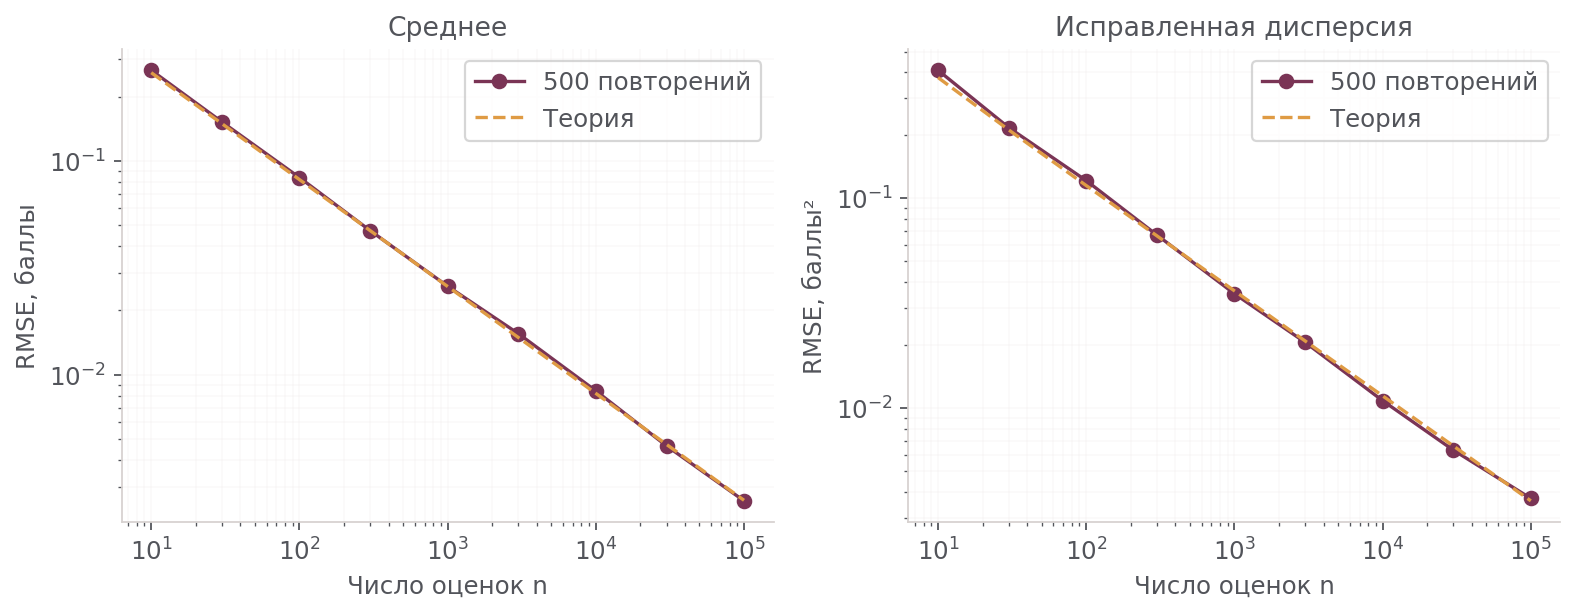

In [66]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,metric,title,unit in zip(axes,['mean','variance'],['Среднее','Исправленная дисперсия'],['баллы','баллы²']):
    ax.loglog(sizes,result[metric+'_rmse'],'o-',label='500 повторений',color='#7a3455')
    ax.loglog(sizes,result[metric+'_rmse_theory'],'--',label='Теория',color='#df9b44')
    ax.set(xlabel='Число оценок n',ylabel='RMSE, '+unit,title=title)
    ax.grid(alpha=.2,which='both')
    ax.legend()
fig.tight_layout()
path=ROOT/'reports/figures/generator_convergence.png'
fig.savefig(path,dpi=160,bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(path)))

### resume

При увеличении объёма с 10 до 100 000 RMSE среднего уменьшилась с 0.2658 до 0.0026 балла, а RMSE исправленной дисперсии - с 0.4071 до 0.0037 балла².
При n = 100 000 теория даёт соответственно 0.0026 и 0.0036.

Результаты согласуются с теоретическим уменьшением ошибки порядка 1/√n и иллюстрируют состоятельность оценок для фиксированного распределения генератора. Конечный эксперимент сам по себе не доказывает предел. Расхождение с реальными данными, найденное ранее, относится к модели и от числа генераций не исчезает.

<a id="rejection"></a>

## Второй алгоритм: отбор с отклонением

Источник раздела: [06_rejection_generator.ipynb](sprint2/06_rejection_generator.ipynb).

### Второй алгоритм: отбор с отклонением
### Description

Оставляем распределение качества при крепости 12% об. и k = 720. Меняем только способ генерации.
Выбираем один из возможных баллов равновероятно. Частые баллы принимаем чаще, редкие - реже; отклонённую попытку повторяем.
Модель обучена на train. Test не используем.

In [67]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
# Backend задаёт Jupyter.
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file())
sys.path.insert(0,str(ROOT/'src'))
from wine_stats.data import load_wines
from wine_stats.split import split_wines
from wine_stats.generator import quality_distribution, inverse_cdf
meta=json.loads((ROOT/'data/processed/alcohol_quality_split.json').read_text())
for name,info in meta['files'].items():
    assert hashlib.sha256((ROOT/'data/raw'/name).read_bytes()).hexdigest()==info['sha256']
df=load_wines(ROOT/'data/raw')
manifest=pd.read_csv(ROOT/'data/processed/alcohol_quality_split.csv')
pd.testing.assert_frame_equal(manifest,split_wines(df,seed=42))
assert manifest.groupby('group_id')['split'].nunique().max()==1
train=df.loc[manifest['split'].eq('train')]

values,p=quality_distribution(train.alcohol,train.quality,12.,k=720)
mu=values@p
variance=((values-mu)**2)@p
moment4=((values-mu)**4)@p
print(f'Среднее модели: {mu:.6f}; дисперсия: {variance:.6f}')

from wine_stats.generator import rejection_sample
from time import perf_counter

from wine_stats.plotting import use_style
use_style()

Среднее модели: 6.375315; дисперсия: 0.670222


### math desc

Пусть m - число предложенных баллов, а p_j - вероятность j-го балла в модели. Выбираем индекс J равномерно и независимо U из [0, 1). Принимаем балл, если U < p_J/p_max.

Вероятность предложить и принять конкретный балл:

$$
P(J=j, A)=\frac{1}{m}\frac{p_j}{p_{\max}}.
$$

Суммируем по баллам и получаем вероятность принятия одной попытки:

$$
P(A)=\frac{1}{m p_{\max}}.
$$

Среди принятых попыток вероятность балла j равна именно требуемой:

$$
P(J=j\mid A)=\frac{P(J=j,A)}{P(A)}=p_j.
$$

Число попыток до принятия имеет геометрическое распределение, поэтому в среднем на одну оценку нужно m·p_max попыток. Чем сильнее вероятности различаются, тем больше отклонений. Вероятность ноль означает, что балл никогда не принимается.

Метод работает и для непрерывных распределений при подходящей мажоранте. Здесь достаточно равномерного предложения на конечном наборе баллов.

Источник: Luc Devroye, *Non-Uniform Random Variate Generation*, Springer, 1986, глава II, §3, с. 40-43. [Книга автора](https://luc.devroye.org/LucDevroye-NonUniformRandomVariateGeneration-10.1007_978-1-4613-8643-8-1986.pdf).

### code

Реализация находится в src/wine_stats/generator.py. Функция возвращает выборку и число попыток. Все принятые значения сохраняются; в конце пакета лишних принятых значений нет. Оба метода используют NumPy для базовой псевдослучайной последовательности.

In [68]:
n=100000
inverse=inverse_cdf(values,p,np.random.default_rng(42).random(n))
rejected,attempts=rejection_sample(values,p,n,seed=42)
frequency=pd.DataFrame({'quality':values,'model':p,
    'inverse_cdf':[(inverse==v).mean() for v in values],
    'rejection':[(rejected==v).mean() for v in values]})
metrics=pd.DataFrame([
    {'method':name,'mean':a.mean(),'variance':a.var(),
     'tv_to_model':.5*np.abs(np.array([(a==v).mean() for v in values])-p).sum()}
    for name,a in [('inverse_cdf',inverse),('rejection',rejected)]])
display(frequency.round(5));display(metrics.round(6))
print(f'Принято {n} из {attempts} попыток: {n/attempts:.2%}')
print(f'Теоретическая доля принятия: {1/(len(p)*p.max()):.2%}')
frequency.to_csv(ROOT/'reports/tables/generator_methods_frequencies.csv',index=False)
metrics.to_csv(ROOT/'reports/tables/generator_methods_metrics.csv',index=False)

,quality,model,inverse_cdf,rejection
0,3,0.00252,0.00253,0.00253
1,4,0.01385,0.01414,0.01331
2,5,0.07557,0.07493,0.07523
3,6,0.50504,0.50344,0.50524
4,7,0.32242,0.32386,0.32170
5,8,0.07809,0.07848,0.07932
6,9,0.00252,0.00262,0.00267


,method,mean,variance,tv_to_model
0,inverse_cdf,6.37788,0.672827,0.002235
1,rejection,6.37891,0.670677,0.001599


Принято 100000 из 352088 попыток: 28.40%
Теоретическая доля принятия: 28.29%


### tests - частоты и скорость

Совпадения отдельных последовательностей не ожидаем: алгоритмы расходуют случайные числа по-разному.
Скорость измеряем после одного прогрева, по медиане 15 запусков, чередуя порядок методов. Включаем генерацию базовых случайных чисел, но не поиск соседей - распределение уже зафиксировано. Это время наших реализаций на данной машине, а не универсальный рейтинг алгоритмов.

,method,n,median_ms,q25_ms,q75_ms
0,inverse_cdf,100000,1.606,1.576,1.876
1,rejection,100000,4.015,3.935,4.318


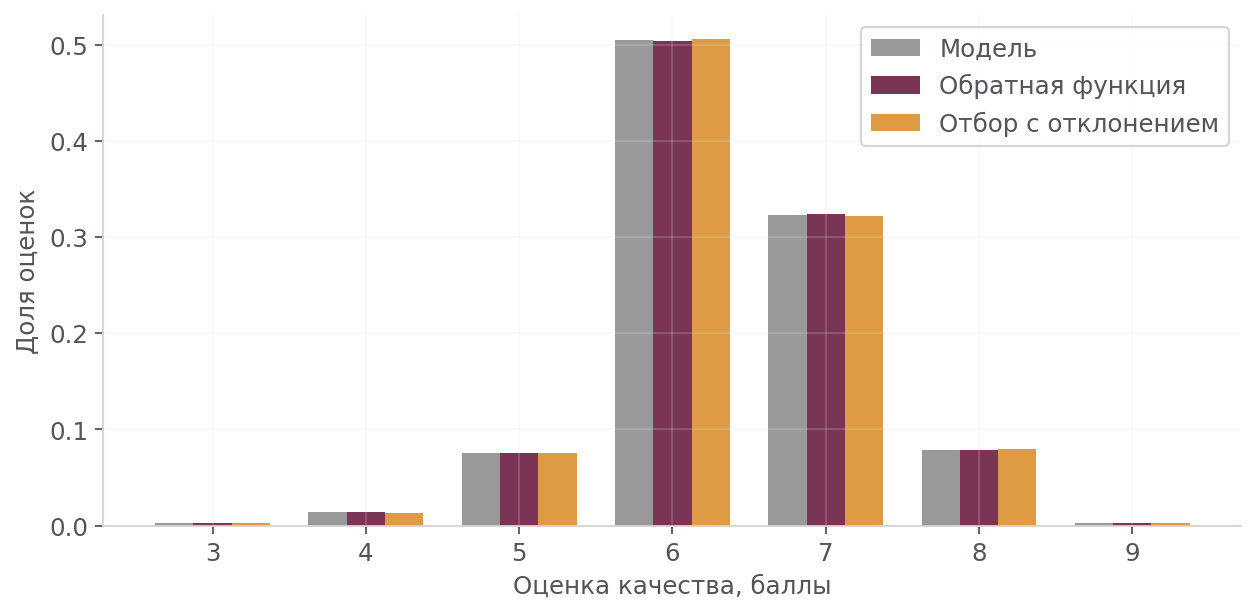

In [69]:
timings={'inverse_cdf':[],'rejection':[]}
def run_method(name,seed):
    if name=='inverse_cdf':
        return inverse_cdf(values,p,np.random.default_rng(seed).random(n))
    return rejection_sample(values,p,n,seed=seed)[0]
for name in timings:run_method(name,0)
for repeat in range(15):
    order=list(timings) if repeat%2==0 else list(reversed(timings))
    for name in order:
        start=perf_counter()
        run_method(name,100+repeat)
        timings[name].append(1000*(perf_counter()-start))
benchmark=pd.DataFrame([{'method':name,'n':n,'median_ms':np.median(t),
    'q25_ms':np.quantile(t,.25),'q75_ms':np.quantile(t,.75)} for name,t in timings.items()])
display(benchmark.round(3))
benchmark.to_csv(ROOT/'reports/tables/generator_methods_timing.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
x=np.arange(len(values));w=.25
for offset,col,label,color in [(-w,'model','Модель','#999999'),(0,'inverse_cdf','Обратная функция','#7a3455'),(w,'rejection','Отбор с отклонением','#df9b44')]:
    ax.bar(x+offset,frequency[col],width=w,label=label,color=color)
ax.set(xticks=x,xticklabels=values,xlabel='Оценка качества, баллы',ylabel='Доля оценок')
ax.legend();fig.tight_layout()
path=ROOT/'reports/figures/generator_methods.png'
fig.savefig(path,dpi=160);plt.close(fig);display(Image(filename=str(path)))

### resume

Для 100 000 оценок расстояние полной вариации до заданного распределения составило 0.00223 у обратной функции и 0.00160 у отбора с отклонением. Это ошибки двух конечных выборок, а не доказательство превосходства одного метода.

Принято 28.40% попыток при теоретических 28.29%. Медианное время для текущей машины приведено в таблице выше.

Оба метода генерируют одно и то же распределение. Для нашей короткой таблицы вероятностей оставляем обратную функцию основной: она не тратит попытки на отклонения. Отбор полезен как альтернативный подход, когда легко найти предложение и ограничить отношение вероятностей, а обращать функцию распределения неудобно.

Автотесты проверяют частоты, нулевые вероятности, вырожденный случай, пустую выборку, воспроизводимость и неверные параметры (tests/test_rejection.py).

<a id="resume2"></a>

## Lab resume

Метод обратной функции и отбор с отклонением воспроизводят одно заданное распределение.
Проверены частоты, границы, допустимые значения и воспроизводимость; автотесты запускаются командой `python -m pytest -q`.
При увеличении числа генераций ошибки среднего и дисперсии уменьшаются.

На 1302 тестовых винах генератор занижает среднюю оценку примерно на 0,048 балла.
Общий разброс близок к реальному, но полное совпадение распределений не установлено.
Увеличение числа генераций не исправляет ошибку модели. Отдельный тест независимости
последовательности пока не выполнен.

### cat_mark_table

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| | [Генератор](#generator) | | Метод обратной функции и математическое обоснование автора |
| | [Реальные данные](#comparison) | | Среднее, дисперсия, квантили, частоты и ограничение модели |
| | [Сходимость](#convergence) | | Повторные оценки среднего и дисперсии |
| | [Второй метод](#rejection) | | Отбор с отклонением, частоты и сравнение времени |
| | [Автотесты](../tests/) | | Проверки реализации генераторов и моделей |
| | [Литература](../references/README.md) | | UCI, первичная статья, Devroye и документация методов |

Сайт в `WebSite/` дополняет ноутбук.